# BÀI THỰC HÀNH 4
## SO SÁNH SỰ TƯƠNG ĐỒNG CỦA CÁC HÌNH ẢNH SỬ DỤNG WAVELET, PYTHON


# 1. PROBLEM DEFINITION – XÁC ĐỊNH BÀI TOÁN

## 1.1. Đặt vấn đề

Trong lĩnh vực xử lý ảnh, việc xác định mức độ tương đồng giữa hai hình ảnh là một nhiệm vụ quan trọng. Hai hình ảnh có thể thể hiện cùng một đối tượng nhưng khác nhau về góc nhìn hoặc một số đặc điểm hình ảnh.

Bài thực hành này nghiên cứu phương pháp sử dụng biến đổi Wavelet để trích xuất đặc trưng hình ảnh, tạo mã băm (Wavelet Hash) và sử dụng khoảng cách Hamming để đánh giá mức độ tương đồng giữa các hình ảnh.

## 1.2. Mục tiêu

- Tìm hiểu và sử dụng thư viện PyWavelets trong Python.
- Trích xuất thông tin đặc trưng của hình ảnh bằng biến đổi Wavelet.
- Tạo mã băm từ các hệ số Wavelet đã lượng tử hóa.
- So sánh mã băm bằng khoảng cách Hamming.
- Đánh giá khả năng phân biệt giữa các cặp ảnh tương đồng và không tương đồng.

## 1.3. Phát biểu bài toán

Cho hai hình ảnh đầu vào, hệ thống thực hiện trích xuất đặc trưng Wavelet và tạo mã băm tương ứng cho từng ảnh.

Sau đó, tính khoảng cách Hamming giữa hai mã băm để xác định mức độ tương đồng.

**Đầu vào:**
- Tập hợp hình ảnh từ bộ dữ liệu COIL-100.
- Các cặp ảnh được xác định là tương đồng hoặc không tương đồng.

**Đầu ra:**
- Mã băm của từng hình ảnh.
- Khoảng cách Hamming giữa hai hình ảnh.
- Kết quả phân loại cặp ảnh tương đồng hoặc không tương đồng.

## 1.4. Phạm vi thực nghiệm

Sử dụng bộ dữ liệu COIL-100, trong đó các hình ảnh cùng một đối tượng được chụp ở những góc xoay khác nhau.

Phạm vi thực nghiệm tập trung vào phương pháp Wavelet Hash và đánh giá kết quả thông qua các chỉ số Accuracy, Sensitivity, Specificity và đường cong ROC.



# 2. DATASET DESCRIPTION – MÔ TẢ DỮ LIỆU

## 2.1. Giới thiệu bộ dữ liệu

Bài thực hành sử dụng bộ dữ liệu COIL-100 (Columbia Object Image Library), một tập dữ liệu hình ảnh gồm nhiều đối tượng được chụp ở các góc nhìn khác nhau.

Bộ dữ liệu được sử dụng để nghiên cứu và thực nghiệm phương pháp so sánh mức độ tương đồng giữa các hình ảnh của cùng một đối tượng và giữa các đối tượng khác nhau.

## 2.2. Nguồn dữ liệu

- Tên bộ dữ liệu: COIL-100.
- Đơn vị phát triển: Columbia University.
- Nguồn tải dữ liệu: [https://www.kaggle.com/datasets/jessicali9530/coil100/data]
- Định dạng dữ liệu: Các tệp hình ảnh.

## 2.3. Quy tắc đặt tên hình ảnh

Tên tệp hình ảnh có dạng:

`objX__Y.png`

Trong đó:
- `X`: mã định danh đối tượng.
- `Y`: góc xoay của đối tượng (độ).

Thông tin này được sử dụng để xác định các cặp ảnh tương đồng và không tương đồng trong quá trình thực nghiệm.

## 2.4. Tiêu chí xác định nhãn

- Cặp ảnh tương đồng: hai ảnh có cùng mã định danh đối tượng.
- Cặp ảnh không tương đồng: hai ảnh có mã định danh đối tượng khác nhau.

Nhãn Ground Truth được xác định dựa trên mã đối tượng trong tên tệp.


### 2.5. Đặc điểm và thông tin bộ dữ liệu

EDA xác nhận bộ dữ liệu có **7.200 ảnh COIL-100**, gồm **100 Object ID** với **72 ảnh cho mỗi đối tượng**. Tên ảnh theo dạng `objX__Y.png`, trong đó X là Object ID và Y là góc xoay.

| Thuộc tính | Kết quả kiểm tra |
|---|---:|
| Số ảnh | 7.200 |
| Số Object ID | 100 |
| Số ảnh mỗi Object ID | 72 |
| Số góc xoay | 72 |
| Dải góc và bước góc | 0°–355°, bước 5° |
| Số ảnh tại mỗi góc | 100 |
| Kích thước ảnh nguồn | 128 × 128 pixels |
| Chế độ màu ảnh nguồn | RGB |
| Định dạng | PNG |

Mỗi Object ID có ảnh tại đủ 72 góc xoay. Cell 17 xác nhận toàn bộ ảnh nguồn có kích thước 128×128, chế độ RGB và định dạng PNG; các ảnh được chuyển sang Grayscale ở bước tiền xử lý.



# 3. EXPLORATORY DATA ANALYSIS (EDA) – KHÁM PHÁ DỮ LIỆU

## 3.1. Mục tiêu khám phá dữ liệu

Giai đoạn khám phá dữ liệu (EDA) được thực hiện nhằm tìm hiểu cấu trúc và đặc điểm của bộ dữ liệu COIL-100 trước khi tiến hành tiền xử lý và trích xuất đặc trưng.

Các nội dung khảo sát bao gồm:

- Kiểm tra số lượng hình ảnh trong bộ dữ liệu.
- Thống kê số lượng đối tượng và số hình ảnh tương ứng với từng đối tượng.
- Khảo sát góc xoay được ghi nhận trong tên tệp.
- Kiểm tra định dạng, kích thước và chế độ màu của hình ảnh.
- Trực quan hóa một số hình ảnh đại diện.

Thông qua quá trình này, có thể đánh giá tính đầy đủ, tính nhất quán và đặc điểm của dữ liệu đầu vào.



## 3.2. Khai báo thư viện và đường dẫn dữ liệu

Trước khi thực hiện khám phá dữ liệu, cần khai báo các thư viện hỗ trợ xử lý đường dẫn, đọc hình ảnh, thống kê và trực quan hóa dữ liệu.


In [1]:

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# Đường dẫn bộ dữ liệu
DATASET_DIR = Path("coil-100/coil-100")

# Kiểm tra thư mục dữ liệu
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset: {DATASET_DIR.resolve()}"
    )

# Thu thập danh sách ảnh
image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}

image_files = sorted([
    file for file in DATASET_DIR.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
])

print("Dataset:", DATASET_DIR.resolve())
print("Tổng số hình ảnh:", len(image_files))


Dataset: D:\lab4\coil-100\coil-100
Tổng số hình ảnh: 7200



## 3.3. Thống kê số lượng hình ảnh theo đối tượng

Dựa trên quy tắc đặt tên tệp `objX__Y.png`, tiến hành trích xuất mã định danh đối tượng từ tên tệp.

Sau đó, thống kê số lượng hình ảnh thuộc từng đối tượng nhằm kiểm tra tính đồng đều và mức độ đầy đủ của bộ dữ liệu.


In [2]:

import re

# Trích xuất mã đối tượng và góc xoay
pattern = re.compile(r"obj(\d+)__(\d+)\.png$", re.IGNORECASE)

records = []

for file in image_files:
    match = pattern.match(file.name)

    if match:
        records.append({
            "filename": file.name,
            "object_id": int(match.group(1)),
            "angle": int(match.group(2))
        })

# Tạo DataFrame
df_images = pd.DataFrame(records)

# Thống kê số ảnh theo đối tượng
object_counts = df_images.groupby("object_id").size()

print("Số file đúng định dạng:", len(df_images))
print("Số lượng đối tượng:", df_images["object_id"].nunique())
print("\nThống kê số ảnh trên mỗi đối tượng:")
print(object_counts.describe())

# Kiểm tra số lượng ảnh của từng đối tượng
print("\nSố lượng ảnh theo từng đối tượng:")
print(object_counts.value_counts().sort_index())

# Kiểm tra đối tượng không đủ 72 ảnh
incomplete_objects = object_counts[object_counts != 72]

if incomplete_objects.empty:
    print("\nTất cả đối tượng đều có đủ 72 ảnh.")
else:
    print("\nCác đối tượng có số ảnh khác 72:")
    print(incomplete_objects)


Số file đúng định dạng: 7200
Số lượng đối tượng: 100

Thống kê số ảnh trên mỗi đối tượng:
count    100.0
mean      72.0
std        0.0
min       72.0
25%       72.0
50%       72.0
75%       72.0
max       72.0
dtype: float64

Số lượng ảnh theo từng đối tượng:
72    100
Name: count, dtype: int64

Tất cả đối tượng đều có đủ 72 ảnh.


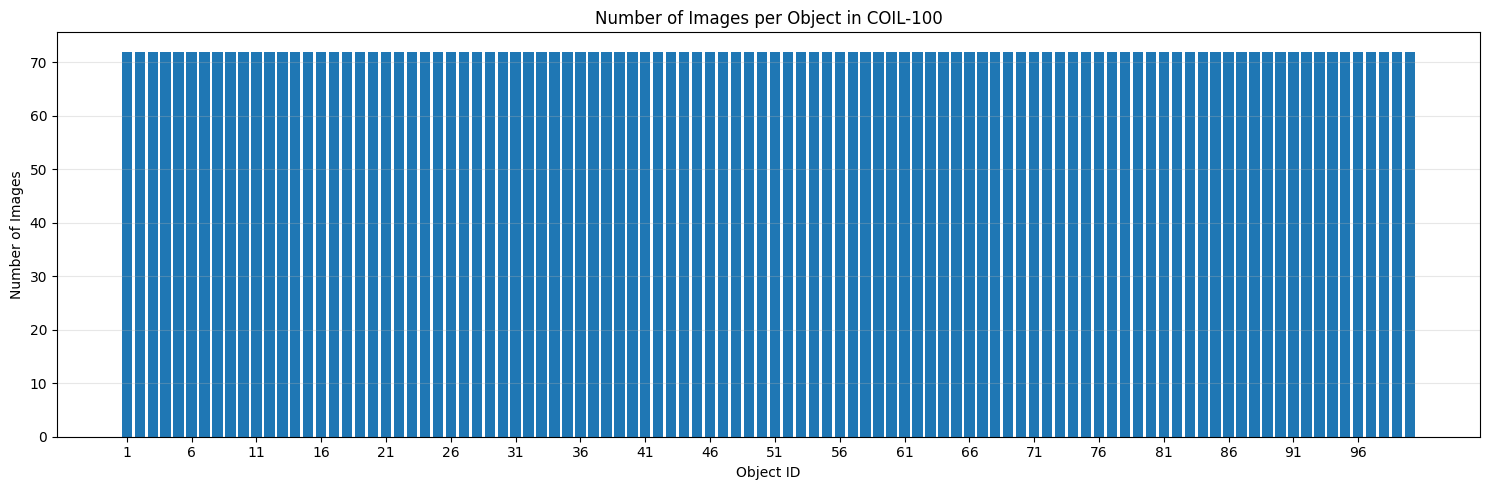

In [3]:

plt.figure(figsize=(15, 5))

plt.bar(
    object_counts.index,
    object_counts.values
)

plt.xlabel("Object ID")
plt.ylabel("Number of Images")
plt.title("Number of Images per Object in COIL-100")
plt.xticks(range(1, 101, 5))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### 3.3.1. Nhận xét kết quả thống kê

Thông qua kết quả thống kê và biểu đồ số lượng hình ảnh theo từng đối tượng, có thể nhận thấy:

- Bộ dữ liệu có 100 đối tượng khác nhau.
- Mỗi đối tượng có 72 hình ảnh.
- Tổng số hình ảnh là 7.200, phân bố đồng đều giữa các đối tượng.
- Không có sự chênh lệch về số lượng hình ảnh giữa các đối tượng (theo kết quả thống kê).

**Kết luận:** Bộ dữ liệu có số lượng hình ảnh đồng đều giữa các đối tượng, tạo điều kiện thuận lợi cho việc xây dựng các cặp ảnh tương đồng và không tương đồng trong các bước thực nghiệm tiếp theo.



## 3.4. Khảo sát góc xoay của hình ảnh

Bộ dữ liệu COIL-100 chứa các hình ảnh của cùng một đối tượng được ghi nhận ở nhiều góc xoay khác nhau.

Trong bước này, tiến hành trích xuất thông tin góc xoay từ tên tệp để xác định phạm vi góc chụp, khoảng cách giữa các góc và mức độ đầy đủ của dữ liệu.


In [4]:

# Thống kê các góc xoay
angle_counts = df_images.groupby("angle").size()

print("Số lượng góc xoay khác nhau:", df_images["angle"].nunique())
print("\nDanh sách góc xoay:")
print(sorted(df_images["angle"].unique()))

print("\nSố ảnh theo từng góc:")
print(angle_counts.describe())

# Kiểm tra các góc xoay có số ảnh khác 100
print("\nCác góc có số ảnh khác 100:")
print(angle_counts[angle_counts != 100])


Số lượng góc xoay khác nhau: 72

Danh sách góc xoay:
[np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(65), np.int64(70), np.int64(75), np.int64(80), np.int64(85), np.int64(90), np.int64(95), np.int64(100), np.int64(105), np.int64(110), np.int64(115), np.int64(120), np.int64(125), np.int64(130), np.int64(135), np.int64(140), np.int64(145), np.int64(150), np.int64(155), np.int64(160), np.int64(165), np.int64(170), np.int64(175), np.int64(180), np.int64(185), np.int64(190), np.int64(195), np.int64(200), np.int64(205), np.int64(210), np.int64(215), np.int64(220), np.int64(225), np.int64(230), np.int64(235), np.int64(240), np.int64(245), np.int64(250), np.int64(255), np.int64(260), np.int64(265), np.int64(270), np.int64(275), np.int64(280), np.int64(285), np.int64(290), np.int64(295), np.int64(300), np.int64(305), np.int64(310), np.int64(315), np.int64


### 3.4.1. Nhận xét kết quả khảo sát góc xoay

Kết quả thống kê cho thấy bộ dữ liệu có 72 góc xoay khác nhau, từ 0° đến 355°, với khoảng cách giữa hai góc liên tiếp là 5°.

Tại mỗi góc xoay có đúng 100 hình ảnh, tương ứng với 100 đối tượng trong bộ dữ liệu. Độ lệch chuẩn của số lượng ảnh theo góc xoay bằng 0, cho thấy dữ liệu được phân bố đồng đều.

**Kết luận:** Bộ dữ liệu cung cấp đầy đủ các góc nhìn của từng đối tượng, tạo điều kiện thuận lợi để xây dựng các cặp ảnh tương đồng ở những góc xoay khác nhau.


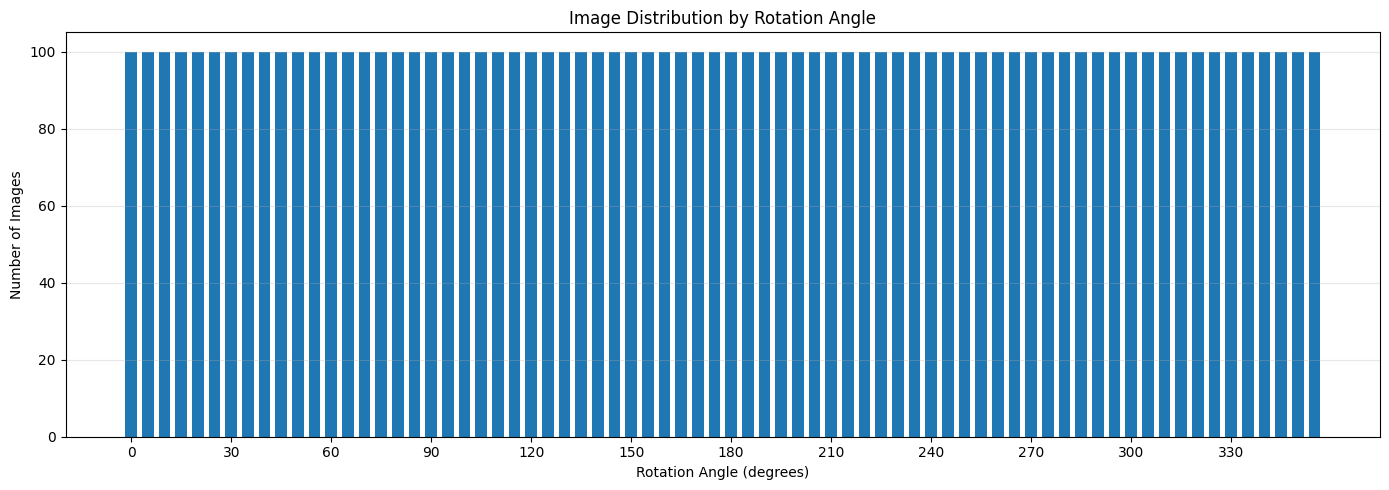

In [5]:

plt.figure(figsize=(14, 5))

plt.bar(
    angle_counts.index,
    angle_counts.values,
    width=3.5
)

plt.xlabel("Rotation Angle (degrees)")
plt.ylabel("Number of Images")
plt.title("Image Distribution by Rotation Angle")

plt.xticks(range(0, 360, 30))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



**Nhận xét biểu đồ:**

Biểu đồ được sử dụng nhằm trực quan hóa sự phân bố số lượng hình ảnh theo từng góc xoay, giúp dễ dàng quan sát và đánh giá mức độ đồng đều của bộ dữ liệu.

Qua biểu đồ có thể nhận thấy:
- Có 72 góc xoay khác nhau, từ 0° đến 355°, với khoảng cách 5°.
- Mỗi góc xoay đều có 100 hình ảnh, tương ứng với 100 đối tượng.
- Các cột có chiều cao bằng nhau, cho thấy số lượng hình ảnh được phân bố đồng đều tại tất cả các góc xoay.

**Ý nghĩa đối với bài toán:**

Việc khảo sát góc xoay giúp xác nhận bộ dữ liệu có đủ các góc nhìn khác nhau của từng đối tượng. Đây là đặc điểm quan trọng đối với bài toán so sánh độ tương đồng hình ảnh, vì hệ thống cần đánh giá khả năng nhận diện cùng một đối tượng ngay cả khi góc nhìn thay đổi.

**Kết luận:** Bộ dữ liệu có cấu trúc cân bằng theo góc xoay, phù hợp để xây dựng các cặp ảnh tương đồng từ cùng một đối tượng ở những góc nhìn khác nhau.



## 3.5. Khảo sát kích thước và chế độ màu hình ảnh

Trong bước này, tiến hành kiểm tra kích thước và chế độ màu của các hình ảnh trong bộ dữ liệu.

Mục tiêu là xác định tính đồng nhất về kích thước và định dạng màu, từ đó lựa chọn phương pháp tiền xử lý phù hợp trước khi thực hiện biến đổi Wavelet.


In [6]:

# Khảo sát kích thước và chế độ màu
image_info = []

for file in image_files:
    with Image.open(file) as img:
        image_info.append({
            "filename": file.name,
            "width": img.width,
            "height": img.height,
            "mode": img.mode,
            "format": img.format
        })

df_image_info = pd.DataFrame(image_info)

print("Thống kê kích thước ảnh:")
print(df_image_info[["width", "height"]].describe())

print("\nCác kích thước ảnh khác nhau:")
print(df_image_info.groupby(["width", "height"]).size())

print("\nPhân bố chế độ màu:")
print(df_image_info["mode"].value_counts())

print("\nPhân bố định dạng:")
print(df_image_info["format"].value_counts())


Thống kê kích thước ảnh:
        width  height
count  7200.0  7200.0
mean    128.0   128.0
std       0.0     0.0
min     128.0   128.0
25%     128.0   128.0
50%     128.0   128.0
75%     128.0   128.0
max     128.0   128.0

Các kích thước ảnh khác nhau:
width  height
128    128       7200
dtype: int64

Phân bố chế độ màu:
mode
RGB    7200
Name: count, dtype: int64

Phân bố định dạng:
format
PNG    7200
Name: count, dtype: int64



### 3.5.1. Nhận xét kết quả khảo sát

**Kết quả thống kê:**

- Bộ dữ liệu gồm 7.200 hình ảnh, tất cả đều có kích thước 128 × 128 pixels.
- Không có sự khác biệt về kích thước giữa các hình ảnh.
- Tất cả hình ảnh đều sử dụng chế độ màu RGB.
- Định dạng PNG được sử dụng thống nhất cho toàn bộ bộ dữ liệu.

**Ý nghĩa đối với bài toán:**

Việc kiểm tra kích thước và chế độ màu giúp xác định các đặc điểm đầu vào cần thiết cho quá trình tiền xử lý.

Các hình ảnh có cùng kích thước giúp giảm sự khác biệt về dữ liệu đầu vào và thuận lợi cho việc áp dụng cùng một quy trình xử lý. Chế độ màu RGB cho phép biểu diễn hình ảnh với ba kênh màu; trong quá trình trích xuất đặc trưng Wavelet, hình ảnh sẽ được chuyển sang ảnh mức xám để xử lý cường độ sáng.

**Kết luận:** Bộ dữ liệu có tính đồng nhất về kích thước, chế độ màu và định dạng. Do đó, không cần thực hiện các thao tác chuẩn hóa kích thước giữa các ảnh, nhưng vẫn cần thực hiện tiền xử lý màu sắc trước khi trích xuất đặc trưng.



## 3.6. Trực quan hóa hình ảnh mẫu

Tiến hành lựa chọn một đối tượng đại diện và hiển thị hình ảnh tại một số góc xoay khác nhau.

Việc trực quan hóa giúp quan sát đặc điểm hình ảnh, sự thay đổi góc nhìn và mức độ khác biệt về mặt thị giác giữa các ảnh của cùng một đối tượng.

Đây cũng là cơ sở trực quan để hình thành các cặp ảnh tương đồng phục vụ quá trình thực nghiệm.


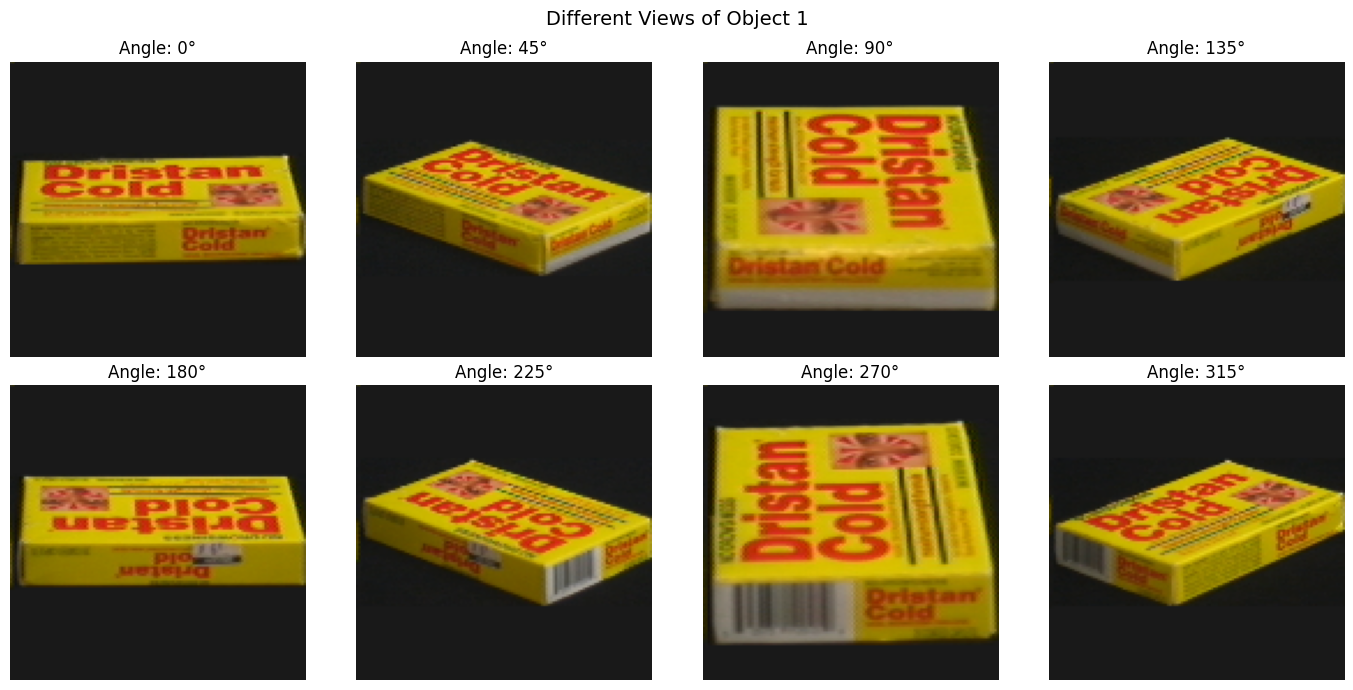

In [7]:

# Chọn một đối tượng đại diện
sample_object = 1

# Các góc xoay cần hiển thị
sample_angles = [0, 45, 90, 135, 180, 225, 270, 315]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, angle in zip(axes.flat, sample_angles):
    filename = f"obj{sample_object}__{angle}.png"
    image_path = DATASET_DIR / filename

    with Image.open(image_path) as img:
        ax.imshow(img)

    ax.set_title(f"Angle: {angle}°")
    ax.axis("off")

plt.suptitle(
    f"Different Views of Object {sample_object}",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 3.6.1. Nhận xét hình ảnh trực quan

Hình ảnh minh họa thể hiện cùng một đối tượng (Object 1) tại tám góc xoay khác nhau, bao gồm 0°, 45°, 90°, 135°, 180°, 225°, 270° và 315°.

Qua quan sát có thể nhận thấy:

- Đối tượng vẫn giữ nguyên đặc điểm nhận dạng cơ bản.
- Góc nhìn thay đổi làm thay đổi vị trí, hướng hiển thị và tỷ lệ quan sát được của các mặt trên vật thể.
- Một số chi tiết như chữ, nhãn và cạnh của hộp có thể thay đổi mức độ hiển thị tùy theo góc nhìn.

**Ý nghĩa đối với bài toán:**

Các hình ảnh này được xem là những trường hợp tương đồng vì chúng cùng thể hiện một đối tượng, mặc dù có sự khác biệt đáng kể về góc nhìn.

Đây là ví dụ thực tế cho bài toán cần giải quyết: đánh giá khả năng nhận diện sự tương đồng giữa hai hình ảnh của cùng một đối tượng khi góc nhìn thay đổi.



## 3.7. Tổng kết quá trình khám phá dữ liệu

Qua quá trình khám phá bộ dữ liệu COIL-100, thu được các kết quả sau:

| Đặc điểm | Kết quả |
|---|---|
| Tổng số hình ảnh | 7.200 |
| Số lượng đối tượng | 100 |
| Số ảnh trên mỗi đối tượng | 72 |
| Số góc xoay | 72 |
| Khoảng cách giữa các góc | 5° |
| Kích thước ảnh | 128 × 128 pixels |
| Chế độ màu | RGB |
| Định dạng | PNG |

Bộ dữ liệu có số lượng hình ảnh đồng đều giữa các đối tượng và góc xoay. Các hình ảnh của cùng một đối tượng thể hiện những góc nhìn khác nhau, phù hợp với yêu cầu xây dựng các cặp ảnh tương đồng và không tương đồng.

Kết quả EDA là cơ sở để xác định các bước tiền xử lý và xây dựng quy trình trích xuất đặc trưng Wavelet trong các giai đoạn tiếp theo.



# 4. DATA PREPROCESSING – TIỀN XỬ LÝ DỮ LIỆU

## 4.1. Mục tiêu tiền xử lý

Sau khi hoàn thành quá trình khám phá dữ liệu, bước tiếp theo là chuẩn bị hình ảnh đầu vào cho quá trình trích xuất đặc trưng bằng biến đổi Wavelet.

Các hình ảnh trong bộ dữ liệu COIL-100 hiện đang ở chế độ màu RGB. Do đó, cần chuyển đổi hình ảnh sang mức xám (Grayscale) để biểu diễn thông tin cường độ sáng dưới dạng ma trận hai chiều.

Các bước tiền xử lý bao gồm:

- Đọc hình ảnh từ bộ dữ liệu.
- Chuyển đổi ảnh RGB sang ảnh Grayscale.
- Kiểm tra kích thước và giá trị điểm ảnh sau chuyển đổi.
- Trực quan hóa kết quả trước và sau tiền xử lý.

**Mục tiêu:** Tạo dữ liệu đầu vào thống nhất, phù hợp với quá trình phân tích hệ số Wavelet ở bước tiếp theo.



## 4.2. Chuyển đổi ảnh RGB sang Grayscale

Ảnh RGB biểu diễn mỗi điểm ảnh thông qua ba kênh màu: Red, Green và Blue.

Trong bài thực hành này, hình ảnh được chuyển sang Grayscale nhằm biểu diễn thông tin cường độ sáng dưới dạng một kênh duy nhất.

Việc chuyển đổi được thực hiện bằng phương thức `convert("L")` của thư viện Pillow.


In [8]:

# Chọn một ảnh mẫu
sample_path = image_files[0]

# Đọc ảnh RGB
with Image.open(sample_path) as img:
    rgb_image = img.convert("RGB")

    # Chuyển sang Grayscale
    gray_image = img.convert("L")

print("Tên ảnh:", sample_path.name)
print("Kích thước ảnh RGB:", rgb_image.size)
print("Chế độ màu RGB:", rgb_image.mode)

print("\nKích thước ảnh Grayscale:", gray_image.size)
print("Chế độ màu Grayscale:", gray_image.mode)


Tên ảnh: obj100__0.png
Kích thước ảnh RGB: (128, 128)
Chế độ màu RGB: RGB

Kích thước ảnh Grayscale: (128, 128)
Chế độ màu Grayscale: L



## 4.3. Trực quan hóa ảnh trước và sau tiền xử lý

Hiển thị ảnh RGB ban đầu và ảnh Grayscale sau chuyển đổi để quan sát sự thay đổi về thông tin màu sắc.

Việc so sánh trực quan giúp xác nhận quá trình chuyển đổi đã được thực hiện đúng và hình ảnh vẫn giữ được các đặc điểm cấu trúc cần thiết.


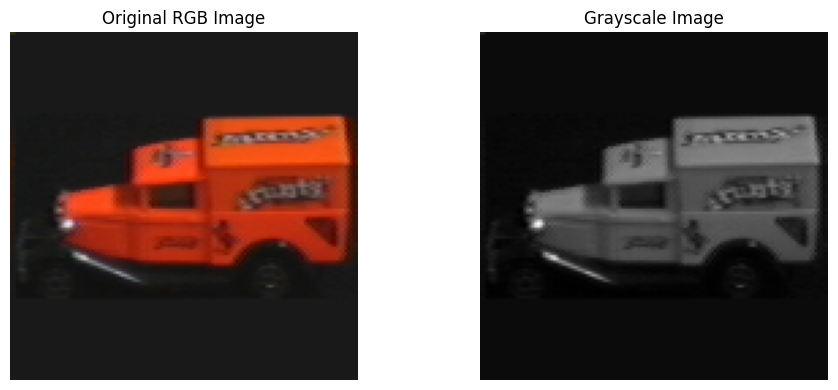

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(rgb_image)
axes[0].set_title("Original RGB Image")
axes[0].axis("off")

axes[1].imshow(gray_image, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()



### 4.3.1. Nhận xét kết quả chuyển đổi

**Kết quả thực nghiệm:**

- Ảnh ban đầu có kích thước 128 × 128 pixels và chế độ màu RGB.
- Sau chuyển đổi, ảnh Grayscale vẫn giữ nguyên kích thước 128 × 128 pixels.
- Chế độ màu chuyển từ RGB sang L (Grayscale).
- Hình ảnh vẫn bảo toàn các đặc điểm cấu trúc cơ bản như hình dạng, đường viền và các chi tiết của đối tượng.

**Ý nghĩa đối với bài toán:**

Việc chuyển đổi sang ảnh Grayscale giúp giảm dữ liệu màu từ ba kênh RGB xuống một kênh cường độ sáng. Điều này giúp đơn giản hóa dữ liệu đầu vào cho quá trình biến đổi Wavelet, vốn sẽ được sử dụng để phân tích các đặc trưng tần số và cấu trúc hình ảnh.

**Kết luận:** Quá trình chuyển đổi RGB sang Grayscale được thực hiện thành công. Ảnh sau chuyển đổi vẫn giữ nguyên kích thước và các đặc điểm cấu trúc cần thiết cho bước trích xuất đặc trưng.



## 4.4. Khảo sát ma trận điểm ảnh sau chuyển đổi

Sau khi chuyển đổi sang Grayscale, mỗi hình ảnh được biểu diễn dưới dạng ma trận hai chiều, trong đó mỗi phần tử tương ứng với cường độ sáng của một pixel.

Trong bước này, tiến hành kiểm tra:
- Kích thước ma trận.
- Kiểu dữ liệu của các phần tử.
- Giá trị pixel nhỏ nhất và lớn nhất.
- Phân bố cường độ sáng của hình ảnh.

Việc khảo sát giúp xác nhận dữ liệu đầu vào trước khi thực hiện biến đổi Wavelet.


In [10]:

# Chuyển ảnh Grayscale thành ma trận NumPy
gray_array = np.array(gray_image)

print("Kích thước ma trận:", gray_array.shape)
print("Kiểu dữ liệu:", gray_array.dtype)

print("\nGiá trị pixel:")
print("Minimum:", gray_array.min())
print("Maximum:", gray_array.max())
print("Mean:", gray_array.mean())
print("Standard deviation:", gray_array.std())

print("\nMa trận pixel (10x10 đầu tiên):")
print(gray_array[:10, :10])


Kích thước ma trận: (128, 128)
Kiểu dữ liệu: uint8

Giá trị pixel:
Minimum: 15
Maximum: 236
Mean: 42.38909912109375
Standard deviation: 31.10501571696871

Ma trận pixel (10x10 đầu tiên):
[[49 47 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]
 [25 25 25 25 25 25 25 25 25 25]]



### 4.4.1. Nhận xét kết quả khảo sát ma trận pixel

**Kết quả thực nghiệm:**

- Ma trận ảnh có kích thước 128 × 128, tương ứng với 16.384 pixel.
- Kiểu dữ liệu là `uint8`, biểu diễn cường độ sáng trong miền giá trị từ 0 đến 255.
- Giá trị pixel nhỏ nhất là 15 và lớn nhất là 236.
- Giá trị trung bình đạt 42,39 và độ lệch chuẩn là 31,11.

**Ý nghĩa đối với bài toán:**

Ma trận pixel là dữ liệu số đầu vào cho quá trình biến đổi Wavelet. Các giá trị cường độ sáng thể hiện sự thay đổi về mức sáng tối giữa các vùng trong hình ảnh.

Những thay đổi này chứa thông tin về cấu trúc, đường biên và chi tiết của đối tượng. Đây là cơ sở để biến đổi Wavelet phân tích và trích xuất đặc trưng hình ảnh.

**Kết luận:** Ảnh Grayscale đã được biểu diễn thành ma trận số hai chiều với kiểu dữ liệu phù hợp cho các phép toán xử lý ảnh tiếp theo.



## 4.5. Khảo sát phân bố cường độ sáng

Histogram biểu diễn tần suất xuất hiện của các mức cường độ sáng trong ảnh Grayscale.

Trong đó:
- Trục hoành biểu diễn giá trị pixel từ 0 đến 255.
- Trục tung biểu diễn số lượng pixel tương ứng với từng mức sáng.

Việc khảo sát Histogram giúp đánh giá đặc điểm phân bố độ sáng của ảnh và hỗ trợ quan sát sự khác biệt giữa các vùng tối, vùng sáng.


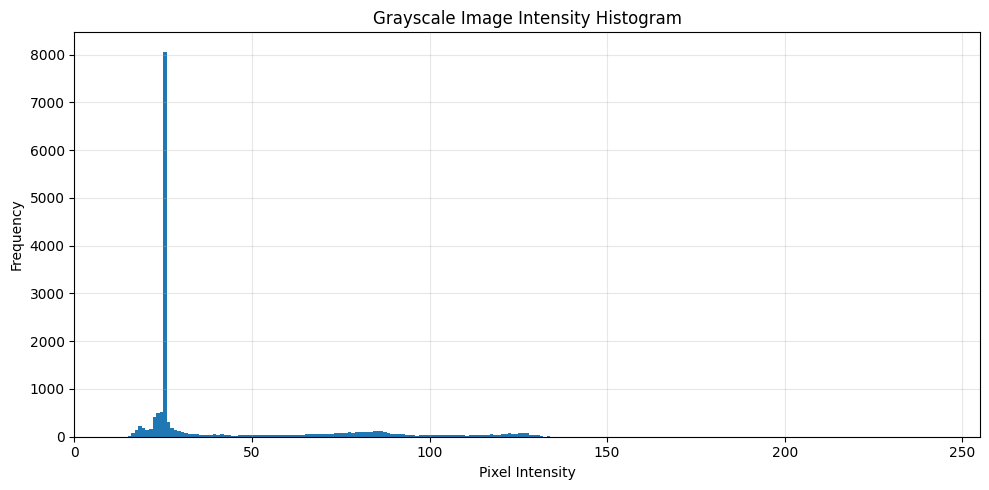

In [11]:

plt.figure(figsize=(10, 5))

plt.hist(
    gray_array.ravel(),
    bins=256,
    range=(0, 256)
)

plt.title("Grayscale Image Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 4.5.1. Nhận xét biểu đồ Histogram

**Mục đích:** Histogram được sử dụng để trực quan hóa tần suất xuất hiện của các mức cường độ sáng trong ảnh Grayscale, qua đó đánh giá đặc điểm phân bố sáng tối của hình ảnh.

**Kết quả quan sát:**

- Các pixel tập trung chủ yếu ở vùng cường độ sáng thấp.
- Xuất hiện một đỉnh phân bố lớn tại mức xám khoảng 25.
- Một số pixel phân bố ở các mức sáng cao hơn, thể hiện những chi tiết sáng của đối tượng.
- Phân bố cường độ sáng không đồng đều và nghiêng về phía vùng tối.

**Ý nghĩa đối với bài toán:**

Biểu đồ cho thấy ảnh có sự chênh lệch về cường độ sáng giữa nền và đối tượng. Những biến đổi cường độ sáng này tạo nên các đặc trưng cấu trúc và đường biên trong hình ảnh.

Biến đổi Wavelet sẽ phân tích những thông tin này ở các thành phần tần số khác nhau, làm cơ sở xây dựng đặc trưng phục vụ so sánh độ tương đồng hình ảnh.

**Kết luận:** Ảnh Grayscale có phân bố cường độ sáng đặc trưng, với phần lớn pixel thuộc vùng tối. Kết quả khảo sát cung cấp thêm thông tin về dữ liệu trước khi thực hiện biến đổi Wavelet.



## 4.6. Tiền xử lý toàn bộ bộ dữ liệu

Sau khi kiểm tra quy trình chuyển đổi trên ảnh mẫu, tiến hành áp dụng phương pháp chuyển đổi RGB sang Grayscale cho toàn bộ 7.200 hình ảnh.

Ảnh sau xử lý được lưu trong một thư mục riêng nhằm bảo toàn dữ liệu gốc và thuận tiện cho các bước thực nghiệm tiếp theo.

Quá trình thực hiện bao gồm:
- Duyệt qua toàn bộ hình ảnh trong bộ dữ liệu.
- Chuyển từng ảnh sang Grayscale.
- Lưu ảnh sau chuyển đổi.
- Kiểm tra số lượng ảnh và tính hợp lệ của dữ liệu đầu ra.


In [12]:

# Thư mục lưu ảnh Grayscale
PROCESSED_DIR = Path("processed/grayscale")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Chuyển đổi toàn bộ ảnh
success_count = 0
error_files = []

for file in image_files:
    try:
        with Image.open(file) as img:
            gray = img.convert("L")
            gray.save(PROCESSED_DIR / file.name)

        success_count += 1

    except Exception as e:
        error_files.append((file.name, str(e)))

print("Tổng ảnh ban đầu:", len(image_files))
print("Số ảnh chuyển đổi thành công:", success_count)
print("Số ảnh lỗi:", len(error_files))
print("Thư mục lưu:", PROCESSED_DIR.resolve())


Tổng ảnh ban đầu: 7200
Số ảnh chuyển đổi thành công: 7200
Số ảnh lỗi: 0
Thư mục lưu: D:\lab4\processed\grayscale



### 4.6.1. Nhận xét kết quả tiền xử lý

**Kết quả thực nghiệm:**

- Tổng số hình ảnh đầu vào: 7.200.
- Số hình ảnh chuyển đổi thành công: 7.200.
- Số hình ảnh xảy ra lỗi: 0.
- Tỷ lệ chuyển đổi thành công: 100%.

**Ý nghĩa đối với bài toán:**

Toàn bộ hình ảnh đã được chuyển từ RGB sang Grayscale và lưu trữ tại thư mục riêng. Việc giữ lại dữ liệu gốc giúp bảo đảm khả năng đối chiếu và tái sử dụng dữ liệu khi cần thiết.

Tập ảnh Grayscale sẽ được sử dụng làm đầu vào cho quá trình trích xuất đặc trưng bằng biến đổi Wavelet.

**Kết luận:** Quá trình tiền xử lý được thực hiện thành công trên toàn bộ 7.200 hình ảnh, không phát sinh lỗi. Dữ liệu đã sẵn sàng cho giai đoạn tiếp theo.



# 5. XÂY DỰNG TẬP DỮ LIỆU CẶP ẢNH

## 5.1. Xác định tiêu chí xây dựng cặp ảnh

Dựa trên cấu trúc của bộ dữ liệu COIL-100, các cặp hình ảnh được xây dựng dựa trên mã định danh đối tượng (Object ID) và góc xoay (Rotation Angle).

Hai loại cặp ảnh được xác định như sau:

- **Cặp ảnh tương đồng (Label = 1):** Hai hình ảnh thuộc cùng một đối tượng nhưng được ghi nhận tại hai góc xoay khác nhau.
- **Cặp ảnh không tương đồng (Label = 0):** Hai hình ảnh thuộc hai đối tượng khác nhau.

Nhãn Ground Truth được xác định dựa trên thông tin Object ID được trích xuất từ tên tệp, không phụ thuộc vào kết quả của thuật toán Wavelet Hash.

Để bảo đảm tính cân bằng cho quá trình đánh giá, tập dữ liệu thực nghiệm được xây dựng với số lượng cặp tương đồng và không tương đồng bằng nhau.

**Mục tiêu:** Tạo tập cặp ảnh có nhãn rõ ràng làm cơ sở tính khoảng cách Hamming và đánh giá khả năng phân biệt hai nhóm ảnh của phương pháp Wavelet Hash.

**Lưu ý:** tập 20.000 cặp gốc cân bằng ở mức toàn cục. Khi tách theo nhóm Object ID để đánh giá (mục 6.9), cặp âm của bộ gốc không còn đủ nhiều trong từng nhóm, nên mục 6.9.2 sinh thêm cặp cân bằng riêng cho từng nhóm.



## 5.2. Tạo các cặp ảnh và gán nhãn Ground Truth

Từ tập ảnh Grayscale, tiến hành xây dựng hai nhóm cặp ảnh:

1. Cặp tương đồng: chọn hai ảnh thuộc cùng Object ID nhưng có góc xoay khác nhau.
2. Cặp không tương đồng: chọn hai ảnh thuộc hai Object ID khác nhau.

Mỗi cặp ảnh được gán nhãn Ground Truth:
- Label = 1: Hai ảnh tương đồng.
- Label = 0: Hai ảnh không tương đồng.

Số lượng cặp ảnh ở hai nhóm được lấy bằng nhau nhằm hạn chế sự mất cân bằng nhãn trong quá trình đánh giá.

Kết quả được lưu thành bảng dữ liệu gồm đường dẫn hai ảnh và nhãn tương ứng.


In [13]:

import re
import random
import pandas as pd
from pathlib import Path

# Thư mục chứa ảnh Grayscale
PROCESSED_DIR = Path("processed/grayscale")

# Đọc danh sách ảnh và phân nhóm theo Object ID
object_images = {}

for file in PROCESSED_DIR.iterdir():
    if not file.is_file():
        continue

    # Tách Object ID và góc xoay từ tên ảnh
    match = re.fullmatch(
        r"obj(\d+)[_-]+(\d+)",
        file.stem,
        flags=re.IGNORECASE
    )

    if match:
        object_id = int(match.group(1))
        angle = int(match.group(2))

        object_images.setdefault(object_id, []).append({
            "path": str(file),
            "angle": angle
        })

# Sắp xếp ảnh theo góc xoay
for object_id in object_images:
    object_images[object_id].sort(key=lambda x: x["angle"])

print("Số đối tượng:", len(object_images))
print("Tổng số ảnh:", sum(len(v) for v in object_images.values()))

print("\nSố ảnh của 5 đối tượng đầu:")
for object_id in sorted(object_images)[:5]:
    print(f"Object {object_id}: {len(object_images[object_id])} ảnh")


Số đối tượng: 100
Tổng số ảnh: 7200

Số ảnh của 5 đối tượng đầu:
Object 1: 72 ảnh
Object 2: 72 ảnh
Object 3: 72 ảnh
Object 4: 72 ảnh
Object 5: 72 ảnh


### 5.3. Sinh cặp ảnh tương đồng và không tương đồng

Dựa trên danh sách ảnh đã được phân nhóm theo Object ID, tiến hành tạo hai nhóm cặp ảnh:

- **Cặp tương đồng:** Chọn ngẫu nhiên hai ảnh khác góc xoay thuộc cùng một đối tượng.
- **Cặp không tương đồng:** Chọn ngẫu nhiên hai ảnh thuộc hai đối tượng khác nhau.

Mỗi nhóm gồm 10.000 cặp ảnh. Việc lấy mẫu ngẫu nhiên được cố định bằng random seed (`PAIR_SEED = 42`) để bảo đảm khả năng tái lập kết quả thực nghiệm.

Cell bên dưới chứa hàm `build_pairs()` thực hiện việc sinh cặp. Nếu file `image_pairs.csv` đã tồn tại (bộ cặp cố định đã dùng cho các kết quả ở mục 6.7 - 6.9), notebook đọc lại file đó để giữ nguyên kết quả; nếu chưa có thì sinh mới bằng `build_pairs()`. Hàm này cũng được dùng lại ở mục 6.9.2 để sinh cặp cân bằng cho từng nhóm Object ID.

Sau khi tạo cặp, mỗi mẫu được lưu cùng nhãn Ground Truth để phục vụ quá trình so sánh bằng Wavelet Hash.


In [14]:
from pathlib import Path
import random

PAIR_SEED = 42
PAIRS_PER_CLASS = 10000   # 10.000 cặp tương đồng + 10.000 cặp không tương đồng

# Nếu bộ cặp cố định đã được tạo từ trước thì dùng lại để giữ nguyên kết quả đã báo cáo
PAIR_FILE_CANDIDATES = [
    Path("outputs") / "image_pairs.csv",
    Path("..") / "outputs" / "image_pairs.csv",
]


def _pair_row(img_a, img_b, object_a, object_b, label):
    return {
        "image_1": img_a["path"],
        "image_2": img_b["path"],
        "object_id_1": object_a,
        "object_id_2": object_b,
        "angle_1": img_a["angle"],
        "angle_2": img_b["angle"],
        "label": label,
    }


def build_pairs(object_ids, n_per_class, seed):
    """Sinh n_per_class cặp tương đồng (label=1) và n_per_class cặp không tương đồng (label=0).

    - Cặp tương đồng: hai ảnh khác góc xoay của cùng một Object ID.
    - Cặp không tương đồng: hai ảnh thuộc hai Object ID khác nhau.
    - Chỉ dùng ảnh của các Object ID trong object_ids; không có cặp trùng (không phân biệt thứ tự).
    - Cố định random seed để tái lập.
    """
    rng = random.Random(seed)
    ids = sorted(object_ids)
    seen, rows = set(), []

    for label in (1, 0):
        count = 0
        while count < n_per_class:
            if label == 1:
                object_a = object_b = rng.choice(ids)
                img_a, img_b = rng.sample(object_images[object_a], 2)
            else:
                object_a, object_b = rng.sample(ids, 2)
                img_a = rng.choice(object_images[object_a])
                img_b = rng.choice(object_images[object_b])

            key = frozenset((img_a["path"], img_b["path"]))
            if key in seen:
                continue
            seen.add(key)
            rows.append(_pair_row(img_a, img_b, object_a, object_b, label))
            count += 1

    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)


existing_pair_file = next((p for p in PAIR_FILE_CANDIDATES if p.is_file()), None)

if existing_pair_file is not None:
    pairs_df = pd.read_csv(existing_pair_file)
    print("Đọc bộ cặp ảnh đã có:", existing_pair_file.resolve())
else:
    pairs_df = build_pairs(set(object_images), PAIRS_PER_CLASS, PAIR_SEED)
    print(f"Không tìm thấy file cặp ảnh -> đã sinh mới (seed={PAIR_SEED})")

required_columns = {"image_1", "image_2", "object_id_1", "object_id_2", "angle_1", "angle_2", "label"}
if not required_columns.issubset(pairs_df.columns) or len(pairs_df) != 2 * PAIRS_PER_CLASS:
    raise ValueError("Bộ cặp ảnh có cấu trúc hoặc số dòng không như mong đợi")

print("Số cặp:", len(pairs_df))
print(pairs_df["label"].value_counts().sort_index())


Đọc bộ cặp ảnh đã có: D:\lab4\outputs\image_pairs.csv
Số cặp: 20000
label
0    10000
1    10000
Name: count, dtype: int64



## 5.4. Kiểm tra và lưu tập cặp ảnh

Sau khi tạo các cặp ảnh, tiến hành kiểm tra tính nhất quán của nhãn Ground Truth, kiểm tra giá trị thiếu và xác định các cặp ảnh trùng lặp.

Các điều kiện kiểm tra:

- Cặp tương đồng phải có cùng Object ID và khác góc xoay.
- Cặp không tương đồng phải có Object ID khác nhau.
- Hai ảnh trong một cặp phải là hai ảnh riêng biệt.
- Không có giá trị bị thiếu.
- Không có cặp ảnh trùng lặp.

Sau khi hoàn tất kiểm tra, tập dữ liệu được lưu dưới định dạng CSV để sử dụng trong các bước thực nghiệm tiếp theo.


In [15]:
# Dùng pairs_df đã được tạo/đọc ở mục 5.3 (không đọc lại file từ đường dẫn khác)
if len(pairs_df) != 20000:
    raise ValueError("Bộ cặp ảnh phải gồm 20.000 dòng")

# Kiểm tra nhãn Ground Truth
valid_similar = (
    (pairs_df["label"] == 1) &
    (pairs_df["object_id_1"] == pairs_df["object_id_2"]) &
    (pairs_df["angle_1"] != pairs_df["angle_2"])
)

valid_dissimilar = (
    (pairs_df["label"] == 0) &
    (pairs_df["object_id_1"] != pairs_df["object_id_2"])
)

# Kiểm tra hai ảnh trong mỗi cặp
valid_images = pairs_df["image_1"] != pairs_df["image_2"]

# Kiểm tra dữ liệu thiếu
missing_values = pairs_df.isnull().sum().sum()

# Kiểm tra cặp trùng lặp, không phân biệt thứ tự
pair_keys = pairs_df.apply(
    lambda row: tuple(sorted(
        [row["image_1"], row["image_2"]]
    )),
    axis=1
)

duplicate_count = pair_keys.duplicated().sum()

# Tổng hợp kết quả
print("KẾT QUẢ KIỂM TRA")
print("-" * 40)
print("Cặp tương đồng hợp lệ:", valid_similar.sum())
print("Cặp không tương đồng hợp lệ:", valid_dissimilar.sum())
print("Cặp có hai ảnh khác nhau:", valid_images.sum())
print("Số giá trị thiếu:", missing_values)
print("Số cặp trùng lặp:", duplicate_count)


# Kiểm tra số lượng cặp hợp lệ theo từng nhóm
all_valid = (
    valid_similar.sum() == (pairs_df["label"] == 1).sum()
    and valid_dissimilar.sum() == (pairs_df["label"] == 0).sum()
    and valid_images.all()
    and missing_values == 0
    and duplicate_count == 0
)

print("Tất cả cặp đều hợp lệ:", all_valid)



KẾT QUẢ KIỂM TRA
----------------------------------------
Cặp tương đồng hợp lệ: 10000
Cặp không tương đồng hợp lệ: 10000
Cặp có hai ảnh khác nhau: 20000
Số giá trị thiếu: 0
Số cặp trùng lặp: 0
Tất cả cặp đều hợp lệ: True


In [16]:

# Tạo thư mục lưu kết quả
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Chỉ lưu khi dữ liệu hợp lệ
if all_valid:
    pairs_file = OUTPUT_DIR / "image_pairs.csv"

    pairs_df.to_csv(
        pairs_file,
        index=False,
        encoding="utf-8"
    )

    print("Đã lưu:", pairs_file.resolve())
    print("Tổng số cặp:", len(pairs_df))
    print(
        "Dung lượng:",
        round(pairs_file.stat().st_size / 1024, 2),
        "KB"
    )
else:
    print("Dữ liệu chưa đạt yêu cầu, chưa lưu!")


Đã lưu: D:\lab4\outputs\image_pairs.csv
Tổng số cặp: 20000
Dung lượng: 1669.08 KB



**Nhận xét kết quả kiểm tra:**

Tập dữ liệu gồm 20.000 cặp ảnh, trong đó có 10.000 cặp tương đồng và 10.000 cặp không tương đồng. Kết quả kiểm tra cho thấy tất cả các cặp đều đáp ứng điều kiện gán nhãn Ground Truth. Không có giá trị thiếu, không có cặp ảnh trùng lặp và hai ảnh trong mỗi cặp đều khác nhau.

**Kết luận:** Tập dữ liệu cặp ảnh đã được xây dựng và kiểm tra thành công, bảo đảm tính hợp lệ và cân bằng nhãn. Dữ liệu được lưu dưới định dạng CSV để phục vụ các bước thực nghiệm tiếp theo.



# 6. TRÍCH XUẤT ĐẶC TRƯNG BẰNG BIẾN ĐỔI WAVELET

## 6.1. Xác định phương pháp và tham số Wavelet

Trong bài thực hành này, biến đổi Wavelet được sử dụng để phân tích hình ảnh thành các thành phần tần số khác nhau, từ đó trích xuất thông tin đặc trưng phục vụ quá trình tạo mã băm.

Phương pháp được triển khai bằng thư viện PyWavelets trong Python.

Các tham số thực nghiệm:

- Wavelet: Daubechies 4 (db4).
- Level: 3.
- Số bit lượng tử hóa: 8 bit.
- Dữ liệu đầu vào: Ảnh Grayscale có kích thước 128 × 128 pixel.

Quá trình biến đổi được thực hiện trên từng hình ảnh. Kết quả thu được là các hệ số Wavelet, biểu diễn thông tin hình ảnh ở nhiều mức phân giải khác nhau.

### 6.2. Thực hiện biến đổi Wavelet 2D trên ảnh mẫu


In [17]:

import pywt
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Cấu hình Wavelet
WAVELET = "db4"
LEVEL = 3
BITS = 8

# Chọn một ảnh mẫu
sample_path = Path("processed/grayscale/obj1__0.png")

# Đọc ảnh Grayscale
sample_image = np.array(
    Image.open(sample_path).convert("L")
)

# Thực hiện biến đổi Wavelet 2D
coeffs = pywt.wavedec2(
    sample_image.astype(np.float32),
    wavelet=WAVELET,
    level=LEVEL
)

# Kiểm tra kết quả
print("Ảnh đầu vào:")
print("Kích thước:", sample_image.shape)
print("Kiểu dữ liệu:", sample_image.dtype)

print("\nThông số Wavelet:")
print("Wavelet:", WAVELET)
print("Level:", LEVEL)
print("Số bit:", BITS)

print("\nCấu trúc hệ số Wavelet:")
for i, coefficient in enumerate(coeffs):
    if i == 0:
        print(f"CA{LEVEL}: {coefficient.shape}")
    else:
        cH, cV, cD = coefficient
        current_level = LEVEL - i + 1
        print(
            f"Level {current_level}: "
            f"cH={cH.shape}, "
            f"cV={cV.shape}, "
            f"cD={cD.shape}"
        )


Ảnh đầu vào:
Kích thước: (128, 128)
Kiểu dữ liệu: uint8

Thông số Wavelet:
Wavelet: db4
Level: 3
Số bit: 8

Cấu trúc hệ số Wavelet:
CA3: (22, 22)
Level 3: cH=(22, 22), cV=(22, 22), cD=(22, 22)
Level 2: cH=(37, 37), cV=(37, 37), cD=(37, 37)
Level 1: cH=(67, 67), cV=(67, 67), cD=(67, 67)



### 6.2.1. Nhận xét kết quả

Kết quả biến đổi Wavelet 2D cho thấy ảnh đầu vào đã được phân rã thành các nhóm hệ số ở ba mức phân giải.

- CA3: Hệ số xấp xỉ, chứa thông tin tổng quát và cấu trúc chính của hình ảnh.
- cH: Hệ số chi tiết theo phương ngang.
- cV: Hệ số chi tiết theo phương dọc.
- cD: Hệ số chi tiết theo đường chéo.

Qua ba mức phân rã, các hệ số Wavelet biểu diễn thông tin hình ảnh ở những mức độ chi tiết khác nhau. Trong đó, hệ số xấp xỉ giữ lại các đặc trưng tổng quát, còn các hệ số chi tiết thể hiện những thay đổi về cường độ pixel và cạnh của đối tượng.

Các hệ số này sẽ được sử dụng làm cơ sở cho bước lượng tử hóa và tạo mã băm hình ảnh.



### 6.3. Trực quan hóa các hệ số Wavelet

Sau khi thực hiện biến đổi Wavelet 2D, ảnh đầu vào được phân rã thành các nhóm hệ số gồm hệ số xấp xỉ (CA) và các hệ số chi tiết (cH, cV, cD) tại từng mức phân rã.

Ở bước này, tiến hành trực quan hóa các hệ số Wavelet nhằm quan sát đặc trưng thông tin được trích xuất từ ảnh sau quá trình phân rã.

**Mục đích:**
- Quan sát thông tin tổng quát của ảnh thông qua hệ số xấp xỉ CA3.
- Quan sát các thành phần chi tiết theo phương ngang, phương dọc và đường chéo thông qua các hệ số cH, cV và cD.
- So sánh sự thay đổi của các hệ số ở những mức phân rã khác nhau.

**Phương pháp thực hiện:**

Các hệ số Wavelet được lấy từ kết quả biến đổi ở bước trước. Do hệ số có thể chứa cả giá trị âm và dương, sử dụng trị tuyệt đối và chuẩn hóa giá trị về khoảng [0, 1] để thuận tiện cho việc hiển thị bằng ảnh xám.

Kết quả được biểu diễn dưới dạng lưới hình ảnh, giúp quan sát trực quan các thành phần hệ số ở ba mức phân rã.


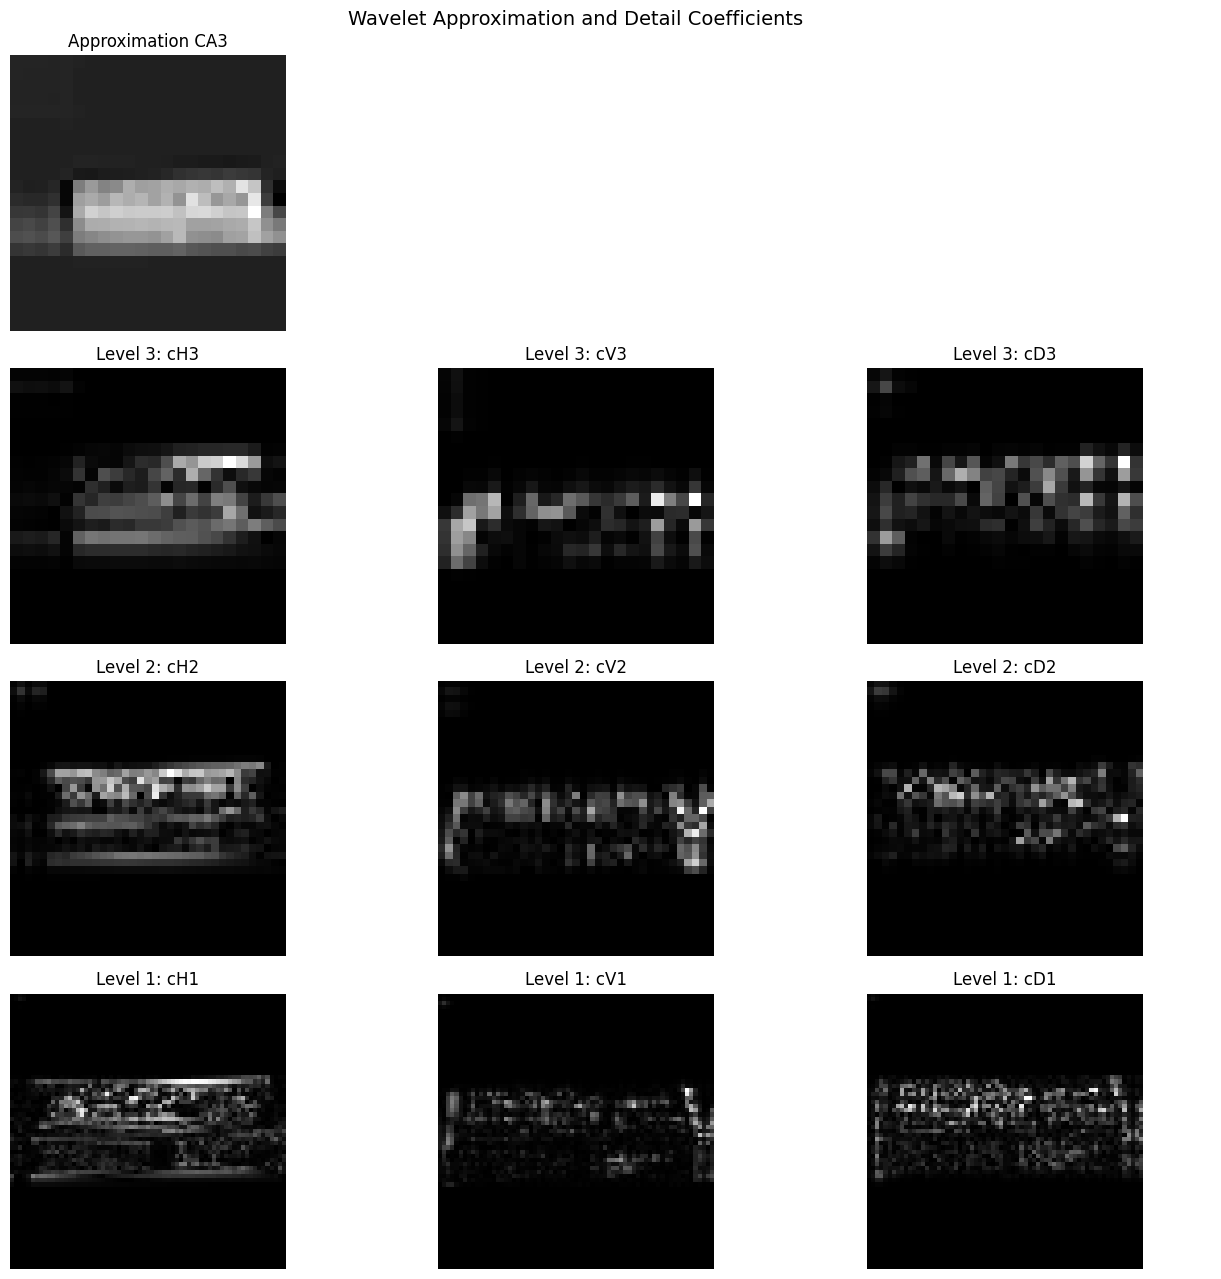

In [18]:
cA3 = coeffs[0]
(cH3, cV3, cD3) = coeffs[1]
(cH2, cV2, cD2) = coeffs[2]
(cH1, cV1, cD1) = coeffs[3]
def normalize_coefficients(data):
    data = np.abs(data)
    return data / (data.max() + 1e-10)
fig, axes = plt.subplots(4, 3, figsize=(13, 13))
axes[0, 0].imshow(normalize_coefficients(cA3), cmap="gray")
axes[0, 0].set_title("Approximation CA3")
axes[0, 0].axis("off")
for ax in axes[0, 1:]:
    ax.axis("off")
detail_levels = [
    (3, [(cH3, "cH3"), (cV3, "cV3"), (cD3, "cD3")]),
    (2, [(cH2, "cH2"), (cV2, "cV2"), (cD2, "cD2")]),
    (1, [(cH1, "cH1"), (cV1, "cV1"), (cD1, "cD1")])
]
for row, (level, bands) in zip(axes[1:], detail_levels):
    for ax, (data, name) in zip(row, bands):
        ax.imshow(normalize_coefficients(data), cmap="gray")
        ax.set_title(f"Level {level}: {name}")
        ax.axis("off")
plt.suptitle("Wavelet Approximation and Detail Coefficients", fontsize=14)
plt.tight_layout()
plt.show()



### 6.3.1. Nhận xét kết quả trực quan hóa

Từ biểu đồ trực quan hóa các hệ số Wavelet, có thể quan sát được sự khác biệt giữa hệ số xấp xỉ và các hệ số chi tiết:

- **Hệ số xấp xỉ (CA3):** Giữ lại những thông tin tổng quát về hình dạng và cấu trúc chính của đối tượng. Hình ảnh sau phân rã có độ phân giải thấp hơn so với ảnh ban đầu.
- **Hệ số chi tiết ngang (cH):** Thể hiện các biến đổi cường độ pixel và đặc trưng cạnh theo phương ngang.
- **Hệ số chi tiết dọc (cV):** Thể hiện các biến đổi theo phương dọc.
- **Hệ số chi tiết chéo (cD):** Thể hiện những thay đổi về chi tiết và cạnh theo phương chéo.

Qua các mức phân rã, các hệ số chi tiết thể hiện những đặc trưng ở các mức độ phân giải khác nhau. Các thành phần này góp phần mô tả cấu trúc và đặc điểm hình ảnh.

**Kết luận:** Kết quả trực quan hóa cho thấy phép biến đổi Wavelet đã tách được thông tin tổng quát và thông tin chi tiết của ảnh. Đây là cơ sở để thực hiện bước lượng tử hóa hệ số và xây dựng mã băm hình ảnh trong các bước tiếp theo.


### 6.4. Lượng tử hóa hệ số Wavelet với thang đo cố định

Mỗi dải hệ số dùng một khoảng lượng tử hóa chung cho mọi ảnh. Hai đầu mút là phân vị 1% và 99%, ước lượng chỉ từ ảnh của 60 Object ID thuộc nhóm train. Hệ số nằm ngoài khoảng bị chặn tại biên rồi lượng tử hóa đều về 256 mức. Các khoảng này được cố định và dùng lại cho mọi ảnh.

Để ước lượng gọn, lấy mẫu đều tối đa 128 hệ số trên mỗi ma trận của từng ảnh train. Nhóm train tách biệt với nhóm calibration dùng chọn threshold và nhóm test.


In [19]:
BITS = 8
BAND_NAMES = ["CA3", "cH3", "cV3", "cD3", "cH2", "cV2", "cD2", "cH1", "cV1", "cD1"]
PROCESSED_DIR = Path("processed/grayscale")
OBJECT_IDS = set(range(1, 101))
TRAIN_OBJECT_IDS = {oid for oid in OBJECT_IDS if oid % 5 in (0, 1, 2)}
CALIBRATION_OBJECT_IDS = {oid for oid in OBJECT_IDS if oid % 5 == 3}
TEST_OBJECT_IDS = {oid for oid in OBJECT_IDS if oid % 5 == 4}
def object_id_from_name(filename):
    match = re.fullmatch(r"obj(\d+)[_-]+(\d+)", Path(filename).stem, re.IGNORECASE)
    if not match:
        raise ValueError(f"Unexpected COIL filename: {filename}")
    return int(match.group(1))
def ordered_coefficients(coeffs_in):
    result = [coeffs_in[0]]
    for level_coeffs in coeffs_in[1:]:
        result.extend(level_coeffs)
    return result
train_paths = sorted(path for path in PROCESSED_DIR.iterdir() if path.is_file() and path.suffix.lower() == ".png" and object_id_from_name(path.name) in TRAIN_OBJECT_IDS)
if not train_paths:
    raise RuntimeError("No training images found for scale calibration.")
calibration_values = {name: [] for name in BAND_NAMES}
for image_path in train_paths:
    with Image.open(image_path) as image:
        image_array = np.asarray(image.convert("L"), dtype=np.float32)
    bands = ordered_coefficients(pywt.wavedec2(image_array, wavelet=WAVELET, level=LEVEL))
    for name, band in zip(BAND_NAMES, bands):
        flat = band.ravel()
        indices = np.linspace(0, len(flat) - 1, min(128, len(flat)), dtype=np.int64)
        calibration_values[name].append(flat[indices])
QUANTIZATION_RANGES = {}
for name in BAND_NAMES:
    values = np.concatenate(calibration_values[name])
    low, high = np.percentile(values, [1, 99])
    if high <= low:
        padding = max(abs(float(low)) * 1e-6, 1e-6)
        low, high = low - padding, high + padding
    QUANTIZATION_RANGES[name] = (float(low), float(high))
def quantize_coefficients(data, band_name, bits=BITS):
    low, high = QUANTIZATION_RANGES[band_name]
    clipped = np.clip(np.asarray(data, dtype=np.float32), low, high)
    normalized = (clipped - low) / (high - low)
    return np.rint(normalized * (2**bits - 1)).astype(np.uint8)
sample_quantized = [quantize_coefficients(data, name) for name, data in zip(BAND_NAMES, ordered_coefficients(coeffs))]
print("Training Object IDs:", len(TRAIN_OBJECT_IDS), "training images:", len(train_paths))
print("Fixed quantization ranges:")
for name in BAND_NAMES:
    print(name, QUANTIZATION_RANGES[name])


Training Object IDs: 60 training images: 4320
Fixed quantization ranges:
CA3 (114.34316505432129, 1613.754649658204)
cH3 (-201.92224548339843, 232.86331375122145)
cV3 (-152.3247769165039, 154.54751647949226)
cD3 (-80.06969276428222, 82.21977081298886)
cH2 (-79.86889945983887, 80.98887458801282)
cV2 (-60.84543296813965, 58.52618362426796)
cD2 (-27.042673110961914, 25.756070270538522)
cH1 (-24.262911491394043, 24.31358154296877)
cV1 (-12.520545129776, 12.663469247817998)
cD1 (-7.3266665697097775, 7.3487040567398445)


### 6.5. Tạo mã nhị phân bằng Gray code

Mỗi mức lượng tử 8 bit được đổi thành Gray code (`g = q XOR (q >> 1)`). Hai mức lượng tử liền kề chỉ khác một bit, giúp giảm số bit lật khi hệ số thay đổi nhẹ. Các bit được đóng gói thành bytes để tiết kiệm bộ nhớ; mọi hash có cùng độ dài logic bằng 8 lần số hệ số Wavelet. Gray code không tự bảo đảm bất biến theo góc xoay, nên hiệu quả được đo trên Object ID test độc lập.


In [20]:
def create_wavelet_hash(quantized_coeffs):
    flat = np.concatenate([np.asarray(array, dtype=np.uint8).ravel() for array in quantized_coeffs])
    gray_values = flat ^ (flat >> 1)
    bits = np.unpackbits(gray_values, bitorder="big")
    return np.packbits(bits, bitorder="big").tobytes()
sample_hash = create_wavelet_hash(sample_quantized)
print("Logical hash length:", len(sample_hash) * 8, "bits; packed bytes:", len(sample_hash))


Logical hash length: 156080 bits; packed bytes: 19510


Mã băm dùng thang lượng tử cố định được hiệu chuẩn trên nhóm train Object ID và Gray code thay cho modulo 2. Độ dài đồng nhất được kiểm tra trước khi tính Hamming. Hiệu quả được đo trên dữ liệu test, không giả định trước.


### 6.6. Tạo mã băm cho toàn bộ tập dữ liệu

Sau khi kiểm tra quá trình tạo mã băm trên một hình ảnh mẫu, ta tiến hành áp dụng quy trình cho toàn bộ tập dữ liệu COIL-100.

Mỗi hình ảnh được thực hiện biến đổi Wavelet, lượng tử hóa hệ số và tạo mã băm. Kết quả được lưu cùng tên ảnh để phục vụ việc tra cứu và so sánh ở các bước tiếp theo.

#### 6.6.1. Áp dụng quy trình tạo mã băm

Tiến hành đọc lần lượt từng ảnh trong tập dữ liệu đã được chuyển sang ảnh Grayscale. Với mỗi ảnh, thực hiện các bước:

1. Đọc ảnh và chuyển dữ liệu ảnh thành ma trận pixel.
2. Thực hiện biến đổi Wavelet với wavelet db4 ở mức phân rã 3.
3. Lượng tử hóa các hệ số Wavelet bằng phương pháp đã trình bày ở mục 6.4.
4. Sử dụng hàm `create_wavelet_hash()` để tạo mã băm nhị phân.

Mã băm được lưu cùng tên tệp ảnh nhằm thuận tiện cho việc tra cứu và so sánh ở các bước tiếp theo.

In [21]:
from pathlib import Path
from PIL import Image
import pywt
import numpy as np
PROCESSED_DIR = Path("processed") / "grayscale"
WAVELET, LEVEL, BITS = "db4", 3, 8
image_paths = sorted(path for path in PROCESSED_DIR.iterdir() if path.is_file() and path.suffix.lower() == ".png")
if len(image_paths) != 7200:
    raise ValueError(f"Expected 7200 grayscale images, got {len(image_paths)}")
def generate_hash_for_image(image_path):
    with Image.open(image_path) as image:
        image_array = np.asarray(image.convert("L"), dtype=np.float32)
    coeffs_image = pywt.wavedec2(image_array, wavelet=WAVELET, level=LEVEL)
    bands = ordered_coefficients(coeffs_image)
    quantized = [quantize_coefficients(data, name) for name, data in zip(BAND_NAMES, bands)]
    return create_wavelet_hash(quantized)
image_hashes = {}
for index, image_path in enumerate(image_paths, start=1):
    image_hashes[image_path.name] = generate_hash_for_image(image_path)
    if index % 500 == 0 or index == len(image_paths):
        print(f"Processed {index}/{len(image_paths)}")


Processed 500/7200
Processed 1000/7200
Processed 1500/7200
Processed 2000/7200
Processed 2500/7200
Processed 3000/7200
Processed 3500/7200
Processed 4000/7200
Processed 4500/7200
Processed 5000/7200
Processed 5500/7200
Processed 6000/7200
Processed 6500/7200
Processed 7000/7200
Processed 7200/7200


In [22]:
expected_coefficients = sum(array.size for array in ordered_coefficients(coeffs))
HASH_BIT_LENGTH = expected_coefficients * BITS
byte_lengths = {len(hash_code) for hash_code in image_hashes.values()}
if len(image_hashes) != 7200 or byte_lengths != {HASH_BIT_LENGTH // 8}:
    raise ValueError(f"Hash count/length mismatch: {len(image_hashes)}, {byte_lengths}")
print("Coefficients per image:", expected_coefficients)
print("Hash length:", HASH_BIT_LENGTH, "bits;", HASH_BIT_LENGTH // 8, "bytes")


Coefficients per image: 19510
Hash length: 156080 bits; 19510 bytes


#### 6.6.2. Nhận xét kết quả

Quá trình tạo mã băm đã xử lý đủ 7.200 ảnh. Mỗi ảnh có 19.510 hệ số Wavelet; mỗi hệ số được mã hóa bằng 8 bit Gray code, nên hash có độ dài logic 156.080 bit (19.510 bytes sau khi đóng gói). Cell kiểm tra ngay phía trên xác nhận số lượng hash và độ dài lưu trữ đồng nhất.


### 6.7. So sánh mã băm bằng khoảng cách Hamming

Khoảng cách Hamming đếm số bit khác nhau tại các vị trí tương ứng. Hash được đóng gói thành bytes, nhưng vẫn giữ cùng độ dài logic; code xác minh độ dài trước khi tính XOR và đếm bit 1.


#### 6.7.1. Tính khoảng cách Hamming cho từng cặp

Trước khi tính, code xác minh đường dẫn của cả hai ảnh tồn tại và có hash tương ứng. XOR kết hợp `bit_count()` đếm chính xác số bit khác nhau giữa hai hash đã đóng gói.

Lưu ý: `int.bit_count()` yêu cầu Python 3.10 trở lên.


In [23]:
from pathlib import Path
# Dùng pairs_df đã được tạo/đọc ở mục 5.3 (không đọc lại file từ đường dẫn khác)
if len(pairs_df) != 20000:
    raise ValueError("Bộ cặp ảnh phải gồm 20.000 dòng")
pairs_df = pairs_df.drop(columns=["hamming_distance"], errors="ignore").copy()
if len({len(hash_code) for hash_code in image_hashes.values()}) != 1:
    raise ValueError("Hash lengths differ")
unique_paths = pd.concat([pairs_df["image_1"], pairs_df["image_2"]]).unique()
missing_paths = [path for path in unique_paths if not Path(path).is_file()]
if missing_paths:
    raise FileNotFoundError(f"Missing image paths: {missing_paths[:3]}")
missing_hashes = {Path(path).name for path in unique_paths} - set(image_hashes)
if missing_hashes:
    raise KeyError(f"Missing hashes: {list(missing_hashes)[:3]}")
def hamming_distance(hash1, hash2):
    if len(hash1) != len(hash2):
        raise ValueError("Hash lengths differ")
    return (int.from_bytes(hash1, "big") ^ int.from_bytes(hash2, "big")).bit_count()
def get_image_name(image_path):
    return Path(str(image_path)).name
distances = []
for _, row in pairs_df.iterrows():
    image_1 = get_image_name(row["image_1"])
    image_2 = get_image_name(row["image_2"])
    distances.append(hamming_distance(image_hashes[image_1], image_hashes[image_2]))
pairs_df["hamming_distance"] = distances
print("Pairs:", len(pairs_df), "distances:", len(distances), "missing:", int(pairs_df["hamming_distance"].isna().sum()))
print(pairs_df["hamming_distance"].describe())


Pairs: 20000 distances: 20000 missing: 0
count    20000.000000
mean     44687.708400
std       9181.875925
min      15072.000000
25%      38366.750000
50%      46225.500000
75%      51630.000000
max      65469.000000
Name: hamming_distance, dtype: float64


### 6.8. Phân tích và trực quan hóa khoảng cách Hamming

Sau khi tính khoảng cách Hamming cho toàn bộ các cặp ảnh, tiến hành phân tích sự phân bố khoảng cách theo hai nhóm nhãn:

- **Nhãn 1:** Hai ảnh tương đồng, thuộc cùng một đối tượng.
- **Nhãn 0:** Hai ảnh không tương đồng, thuộc hai đối tượng khác nhau.

Việc so sánh phân bố khoảng cách giúp đánh giá khả năng phân biệt hai nhóm ảnh của mã băm Wavelet. Nếu thuật toán hoạt động tốt, nhóm ảnh tương đồng thường có khoảng cách Hamming nhỏ hơn nhóm ảnh không tương đồng.

THỐNG KÊ KHOẢNG CÁCH HAMMING THEO NHÃN
-------------------------------------------------------
         count        mean          std      min       25%      50%       75%  \
label                                                                           
0      10000.0  48076.9888  7142.281648  20050.0  43815.00  49208.0  53263.00   
1      10000.0  41298.4280  9727.959419  15072.0  34093.75  41233.0  48630.25   

           max  
label           
0      64356.0  
1      65469.0  

Khoảng cách trung bình:
Cặp tương đồng: 41298.43
Cặp không tương đồng: 48076.99


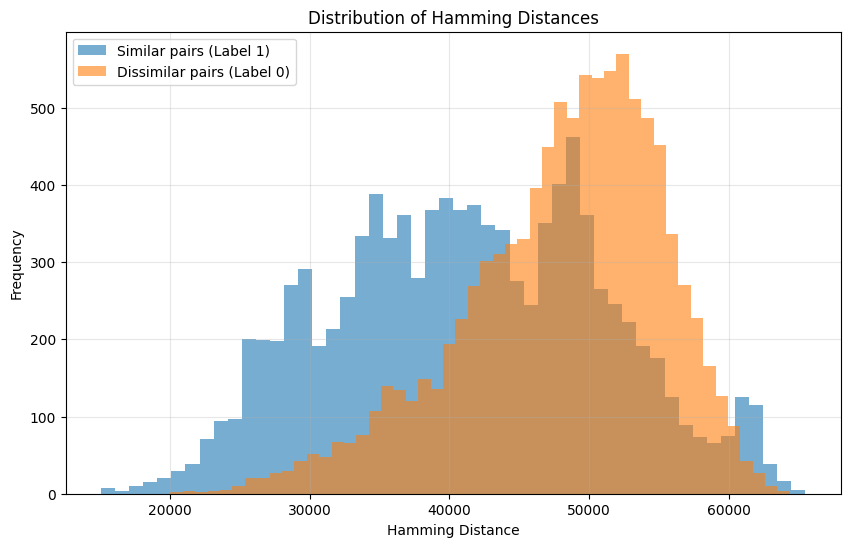

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# Thống kê khoảng cách theo nhãn
distance_stats = pairs_df.groupby("label")["hamming_distance"].describe()

print("THỐNG KÊ KHOẢNG CÁCH HAMMING THEO NHÃN")
print("-" * 55)
print(distance_stats)

# Tính khoảng cách trung bình của từng nhóm
similar_mean = pairs_df[pairs_df["label"] == 1]["hamming_distance"].mean()
dissimilar_mean = pairs_df[pairs_df["label"] == 0]["hamming_distance"].mean()

print("\nKhoảng cách trung bình:")
print(f"Cặp tương đồng: {similar_mean:.2f}")
print(f"Cặp không tương đồng: {dissimilar_mean:.2f}")

# Trực quan hóa phân bố khoảng cách
plt.figure(figsize=(10, 6))

plt.hist(
    pairs_df[pairs_df["label"] == 1]["hamming_distance"],
    bins=50,
    alpha=0.6,
    label="Similar pairs (Label 1)"
)

plt.hist(
    pairs_df[pairs_df["label"] == 0]["hamming_distance"],
    bins=50,
    alpha=0.6,
    label="Dissimilar pairs (Label 0)"
)

plt.xlabel("Hamming Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Hamming Distances")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Nhận xét kết quả:**

Trên toàn bộ 20.000 cặp gốc, khoảng cách Hamming trung bình của cặp cùng đối tượng là **41.298,43**, thấp hơn nhóm khác đối tượng (**48.076,99**). Hai phân bố vẫn chồng lấn; độ lệch chuẩn lần lượt khoảng 9.727,96 và 7.142,28.

Biểu đồ mô tả phân bố khoảng cách của tập cặp đã có. Đánh giá cuối cùng được thực hiện riêng trên test Object ID ở mục 6.9.


### 6.9. Đánh giá theo Object ID giữ riêng

Object ID được chia thành ba nhóm không giao nhau: train dùng hiệu chuẩn thang hệ số, calibration chỉ dùng chọn threshold, test chỉ dùng báo cáo chỉ số cuối. Mục này có hai cách đánh giá:

- **(a) Trên bộ cặp gốc 20.000 cặp (mục 6.9 - 6.9.1):** chỉ giữ các cặp mà cả hai Object ID cùng thuộc một nhóm. Vì cặp âm gốc được lấy trên cả 100 đối tượng nên chỉ còn rất ít cặp âm trong mỗi nhóm, dẫn đến tập test **mất cân bằng nhãn** (377 âm so với 2.032 dương).
- **(b) Trên cặp cân bằng sinh riêng cho từng nhóm (mục 6.9.2):** số cặp dương bằng số cặp âm trong cả calibration và test, nên Accuracy có ý nghĩa so sánh với mức ngẫu nhiên 0,5.

Kết quả (a) được giữ lại để đối chiếu; chỉ số chính để kết luận là kết quả (b).


Object ID counts train/calibration/test: 60 20 20
Calibration pairs: 2380 {0: 376, 1: 2004}
Test pairs: 2409 {0: 377, 1: 2032}
Calibration threshold: 45374.0
TEST accuracy=0.6492; sensitivity=0.6432; specificity=0.6817; precision=0.9159; AUC=0.7105
TN=257, FP=120, FN=725, TP=1307


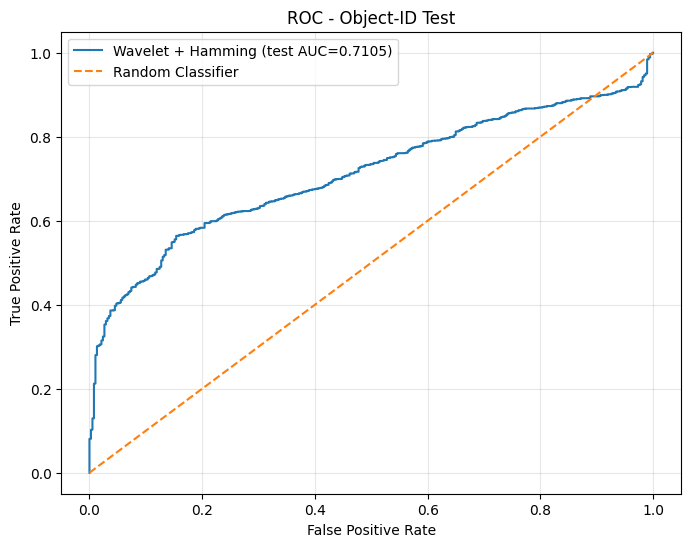

In [25]:
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, confusion_matrix, precision_score
import numpy as np
import matplotlib.pyplot as plt
def pairs_within_group(frame, allowed_ids):
    return frame[frame["object_id_1"].isin(allowed_ids) & frame["object_id_2"].isin(allowed_ids)].copy()
calibration_pairs = pairs_within_group(pairs_df, CALIBRATION_OBJECT_IDS)
test_pairs = pairs_within_group(pairs_df, TEST_OBJECT_IDS)
if calibration_pairs["label"].nunique() != 2 or test_pairs["label"].nunique() != 2:
    raise ValueError("Calibration and test must contain both labels")
y_cal = calibration_pairs["label"].astype(int).to_numpy()
d_cal = calibration_pairs["hamming_distance"].to_numpy()
cal_fpr, cal_tpr, cal_thresholds = roc_curve(y_cal, -d_cal)
valid_thresholds = np.flatnonzero(np.isfinite(cal_thresholds))
if not len(valid_thresholds):
    raise RuntimeError("No finite calibration threshold")
youden = cal_tpr - cal_fpr
best_index = valid_thresholds[np.argmax(youden[valid_thresholds])]
threshold_distance = -cal_thresholds[best_index]
y_true = test_pairs["label"].astype(int).to_numpy()
d_test = test_pairs["hamming_distance"].to_numpy()
y_score = -d_test
predictions = (d_test <= threshold_distance).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
accuracy = accuracy_score(y_true, predictions)
sensitivity = tp / (tp + fn) if tp + fn else 0.0
specificity = tn / (tn + fp) if tn + fp else 0.0
precision = precision_score(y_true, predictions, zero_division=0)
auc_score = roc_auc_score(y_true, y_score)
print("Object ID counts train/calibration/test:", len(TRAIN_OBJECT_IDS), len(CALIBRATION_OBJECT_IDS), len(TEST_OBJECT_IDS))
print("Calibration pairs:", len(calibration_pairs), calibration_pairs["label"].value_counts().sort_index().to_dict())
print("Test pairs:", len(test_pairs), test_pairs["label"].value_counts().sort_index().to_dict())
print("Calibration threshold:", threshold_distance)
print(f"TEST accuracy={accuracy:.4f}; sensitivity={sensitivity:.4f}; specificity={specificity:.4f}; precision={precision:.4f}; AUC={auc_score:.4f}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
fpr, tpr, _ = roc_curve(y_true, y_score)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Wavelet + Hamming (test AUC={auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC - Object-ID Test")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 6.9.1. Nhận xét kết quả trên tập test từ cặp gốc (mất cân bằng)

Ngưỡng **45.374** được chọn bằng Youden J trên 2.380 cặp calibration (376 âm, 2.004 dương). Tập test theo Object ID gồm 2.409 cặp: 377 âm và 2.032 dương.

| Chỉ số trên test | Giá trị |
|---|---:|
| Accuracy | 0.6492 |
| Balanced accuracy (tính từ confusion matrix) | 0.6625 |
| Sensitivity | 0.6432 |
| Specificity | 0.6817 |
| Precision | 0.9159 |
| AUC | 0.7105 |

Confusion matrix: TN=257, FP=120, FN=725, TP=1307. ROC dùng score `-Hamming distance`, nên khoảng cách càng nhỏ thì điểm tương đồng càng cao. Threshold được chọn trên calibration, không chọn trên test.

Tập test này mất cân bằng lớp. Accuracy 0.6492 thấp hơn mức 0.8435 của quy tắc luôn dự đoán lớp dương (2.032/2.409); precision cao cũng cần được đọc cùng tỷ lệ lớp. Balanced accuracy khoảng 0.6625 cho thấy kết quả vượt mức ngẫu nhiên nhưng khả năng phân biệt ở ngưỡng này còn hạn chế. Vì cell 6.9.2 đánh giá trên tập test cân bằng, các chỉ số ở đó phù hợp hơn để tóm tắt khả năng phân loại trên hai lớp cân bằng.


### 6.9.2. Đánh giá trên cặp cân bằng theo từng nhóm Object ID

Cell 73 sinh riêng cho calibration và test mỗi nhóm 2.000 cặp tương đồng và 2.000 cặp không tương đồng. Hai nhóm dùng các Object ID không giao nhau; các cặp được lấy từ nhóm Object ID tương ứng. Output xác nhận mỗi split có 4.000 cặp, cân bằng 2.000/2.000. Threshold được chọn bằng Youden J trên calibration và các chỉ số dưới đây được tính trên test.


Calibration pairs: 4000 {0: 2000, 1: 2000}
Test pairs: 4000 {0: 2000, 1: 2000}
Calibration threshold: 44375.0
TEST accuracy=0.6627; balanced_accuracy=0.6627; sensitivity=0.6230; specificity=0.7025; precision=0.6768; AUC=0.7007
TN=1405, FP=595, FN=754, TP=1246


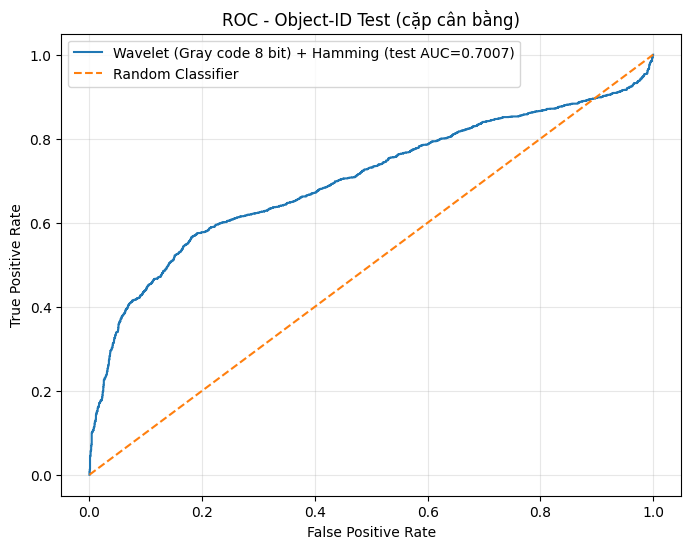

In [26]:
# 6.9.2. Đánh giá trên cặp cân bằng theo từng nhóm Object ID
from sklearn.metrics import (
    roc_curve, roc_auc_score, accuracy_score,
    balanced_accuracy_score, confusion_matrix, precision_score,
)

EVAL_SEED = 2026
EVAL_PAIRS_PER_CLASS = 2000   # mỗi nhóm: 2.000 cặp dương + 2.000 cặp âm


def add_hamming(frame, hashes):
    """Thêm cột hamming_distance dựa trên dict {tên file: hash dạng bytes}."""
    frame = frame.copy()
    frame["hamming_distance"] = [
        hamming_distance(hashes[Path(a).name], hashes[Path(b).name])
        for a, b in zip(frame["image_1"], frame["image_2"])
    ]
    return frame


def evaluate_distances(d_cal, y_cal, d_test, y_test):
    """Chọn ngưỡng bằng Youden J trên calibration, báo cáo chỉ số trên test.
    Điểm tương đồng = -khoảng cách Hamming (khoảng cách nhỏ -> giống nhau hơn)."""
    cal_fpr, cal_tpr, cal_thr = roc_curve(y_cal, -d_cal)
    finite = np.flatnonzero(np.isfinite(cal_thr))
    best = finite[np.argmax((cal_tpr - cal_fpr)[finite])]
    threshold = float(-cal_thr[best])

    pred = (d_test <= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "sensitivity": tp / (tp + fn) if tp + fn else 0.0,
        "specificity": tn / (tn + fp) if tn + fp else 0.0,
        "precision": precision_score(y_test, pred, zero_division=0),
        "auc": roc_auc_score(y_test, -d_test),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


# Sinh cặp cân bằng riêng cho calibration và test (hai nhóm Object ID không giao nhau)
cal_pairs_bal = add_hamming(
    build_pairs(CALIBRATION_OBJECT_IDS, EVAL_PAIRS_PER_CLASS, EVAL_SEED), image_hashes)
test_pairs_bal = add_hamming(
    build_pairs(TEST_OBJECT_IDS, EVAL_PAIRS_PER_CLASS, EVAL_SEED + 1), image_hashes)

assert set(cal_pairs_bal["object_id_1"]) | set(cal_pairs_bal["object_id_2"]) <= CALIBRATION_OBJECT_IDS
assert set(test_pairs_bal["object_id_1"]) | set(test_pairs_bal["object_id_2"]) <= TEST_OBJECT_IDS

y_cal_bal = cal_pairs_bal["label"].astype(int).to_numpy()
y_test_bal = test_pairs_bal["label"].astype(int).to_numpy()
d_cal_bal = cal_pairs_bal["hamming_distance"].to_numpy()
d_test_bal = test_pairs_bal["hamming_distance"].to_numpy()

res_gray = evaluate_distances(d_cal_bal, y_cal_bal, d_test_bal, y_test_bal)

print("Calibration pairs:", len(cal_pairs_bal), cal_pairs_bal["label"].value_counts().sort_index().to_dict())
print("Test pairs:", len(test_pairs_bal), test_pairs_bal["label"].value_counts().sort_index().to_dict())
print("Calibration threshold:", res_gray["threshold"])
print(
    f"TEST accuracy={res_gray['accuracy']:.4f}; balanced_accuracy={res_gray['balanced_accuracy']:.4f}; "
    f"sensitivity={res_gray['sensitivity']:.4f}; specificity={res_gray['specificity']:.4f}; "
    f"precision={res_gray['precision']:.4f}; AUC={res_gray['auc']:.4f}"
)
print(f"TN={res_gray['tn']}, FP={res_gray['fp']}, FN={res_gray['fn']}, TP={res_gray['tp']}")

fpr_bal, tpr_bal, _ = roc_curve(y_test_bal, -d_test_bal)
plt.figure(figsize=(8, 6))
plt.plot(fpr_bal, tpr_bal, label=f"Wavelet (Gray code 8 bit) + Hamming (test AUC={res_gray['auc']:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC - Object-ID Test (cặp cân bằng)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 6.9.3. Nhận xét kết quả trên tập test cân bằng

Threshold **44.375** được chọn trên 4.000 cặp calibration cân bằng. Tập test độc lập theo Object ID gồm 4.000 cặp, cũng cân bằng 2.000 cặp mỗi lớp.

| Chỉ số trên test cân bằng | Giá trị |
|---|---:|
| Accuracy | 0.6627 |
| Balanced accuracy | 0.6627 |
| Sensitivity | 0.6230 |
| Specificity | 0.7025 |
| Precision | 0.6768 |
| AUC | 0.7007 |

Confusion matrix: TN=1405, FP=595, FN=754, TP=1246. Accuracy bằng Balanced accuracy vì test có số lượng hai lớp bằng nhau. AUC 0.7007 cao hơn mức ngẫu nhiên 0.5, cho thấy khoảng cách Hamming có khả năng xếp hạng cặp tương đồng cao hơn cặp không tương đồng ở mức vừa phải. Sensitivity thấp hơn Specificity, nên ở threshold này còn bỏ sót một phần cặp tương đồng.

Đây là kết quả trên 20 Object ID test; các cặp trong cùng split có thể dùng lại ảnh nên không hoàn toàn độc lập.


### 6.10. Thử nghiệm bổ sung: hash chỉ dùng băng xấp xỉ CA3

Hash chính mã hóa 19.510 hệ số, trong đó 13.467 (khoảng 69%) thuộc các dải chi tiết Level 1. Các dải chi tiết tần số cao có thể phản ứng mạnh với thay đổi hướng nhìn; đây là giả thuyết cần đánh giá bằng output.

Cell 76 tạo biến thể CA3-only: dùng 484 hệ số CA3 (22×22), so sánh từng hệ số với median của chính ảnh để tạo 1 bit/hệ số. Hash logic dài 484 bit và được đóng gói thành 61 bytes. Biến thể được đánh giá trên cùng các cặp calibration/test cân bằng như hash chính; kết quả thực tế được trình bày ở cell 77.


Số hash CA3: 7200 | số byte mỗi hash: {61}
                                         threshold  accuracy  balanced_accuracy  sensitivity  specificity  precision     auc
Wavelet toàn bộ hệ số (Gray code 8 bit)    44375.0    0.6627             0.6627        0.623       0.7025     0.6768  0.7007
CA3 + median (1 bit/hệ số)                   111.0    0.7528             0.7528        0.727       0.7785     0.7665  0.8190


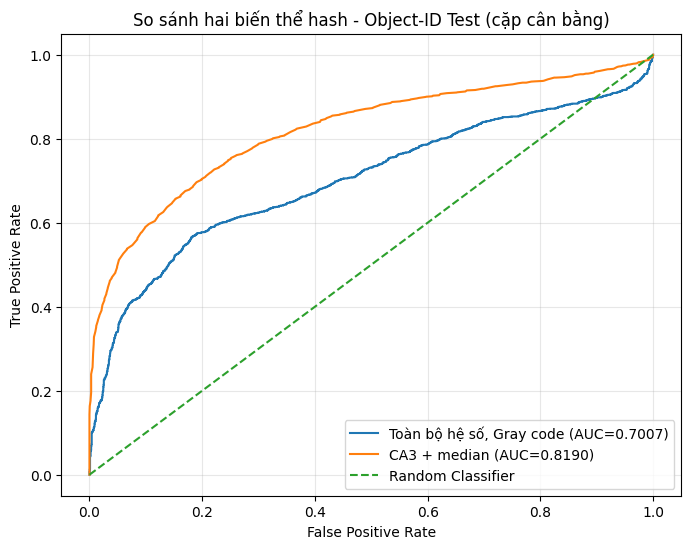

In [27]:
# 6.10. Biến thể hash: băng xấp xỉ CA3, nhị phân hóa theo median (484 bit)
def create_ll_median_hash(image_path):
    with Image.open(image_path) as image:
        image_array = np.asarray(image.convert("L"), dtype=np.float32)
    ca3_only = pywt.wavedec2(image_array, wavelet=WAVELET, level=LEVEL)[0]
    bits = (ca3_only > np.median(ca3_only)).ravel()
    return np.packbits(bits).tobytes()


ll_hashes = {path.name: create_ll_median_hash(path) for path in image_paths}
print("Số hash CA3:", len(ll_hashes), "| số byte mỗi hash:", {len(h) for h in ll_hashes.values()})

cal_ll = add_hamming(cal_pairs_bal, ll_hashes)
test_ll = add_hamming(test_pairs_bal, ll_hashes)

res_ll = evaluate_distances(
    cal_ll["hamming_distance"].to_numpy(), y_cal_bal,
    test_ll["hamming_distance"].to_numpy(), y_test_bal,
)

comparison = pd.DataFrame(
    {"Wavelet toàn bộ hệ số (Gray code 8 bit)": res_gray, "CA3 + median (1 bit/hệ số)": res_ll}
).T[["threshold", "accuracy", "balanced_accuracy", "sensitivity", "specificity", "precision", "auc"]]
print(comparison.round(4).to_string())

fpr_ll, tpr_ll, _ = roc_curve(y_test_bal, -test_ll["hamming_distance"].to_numpy())
plt.figure(figsize=(8, 6))
plt.plot(fpr_bal, tpr_bal, label=f"Toàn bộ hệ số, Gray code (AUC={res_gray['auc']:.4f})")
plt.plot(fpr_ll, tpr_ll, label=f"CA3 + median (AUC={res_ll['auc']:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("So sánh hai biến thể hash - Object-ID Test (cặp cân bằng)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


#### 6.10.1. Nhận xét kết quả so sánh hai biến thể hash

| Chỉ số | Toàn bộ hệ số, Gray code 8 bit | CA3 + median, 1 bit/hệ số |
|---|---:|---:|
| Threshold (calibration) | 44.375 | 111 |
| Accuracy | 0.6627 | 0.7528 |
| Balanced accuracy | 0.6627 | 0.7528 |
| Sensitivity | 0.6230 | 0.7270 |
| Specificity | 0.7025 | 0.7785 |
| Precision | 0.6768 | 0.7665 |
| AUC | 0.7007 | 0.8190 |

Trên cùng tập test cân bằng hiện tại, CA3 + median có AUC cao hơn 0.1183 và Balanced accuracy cao hơn 0.0901 so với hash toàn bộ hệ số. Các chỉ số được tính từ cùng các cặp calibration/test, nhưng việc chọn biến thể dựa trên test có thể làm kết quả lạc quan. Đây là kết quả thăm dò trên 20 Object ID test, chưa đủ để khẳng định CA3 sẽ tốt hơn trên Object ID mới.


### 6.11. Phân tích theo chênh lệch góc xoay

Cell 79 phân nhóm 2.000 cặp tương đồng trong test cân bằng theo chênh lệch góc vòng (5°–180°), rồi tính tỷ lệ nhận đúng ở threshold **44.375**, được chọn trên calibration. Bảng và biểu đồ dưới đây mô tả tỷ lệ theo từng bin; cần diễn giải theo output thực tế, không giả định sensitivity giảm đều theo góc.


                so_cap  khoang_cach_TB  ti_le_nhan_dung
angle_bin                                              
(-0.001, 30.0]     331      37884.7855           0.7341
(30.0, 60.0]       348      40945.8563           0.6207
(60.0, 90.0]       354      42234.4294           0.5989
(90.0, 120.0]      345      42991.2348           0.5594
(120.0, 150.0]     337      41942.2226           0.5816
(150.0, 180.0]     285      39777.7965           0.6526
Specificity trên cặp âm test (tham chiếu): 0.7025


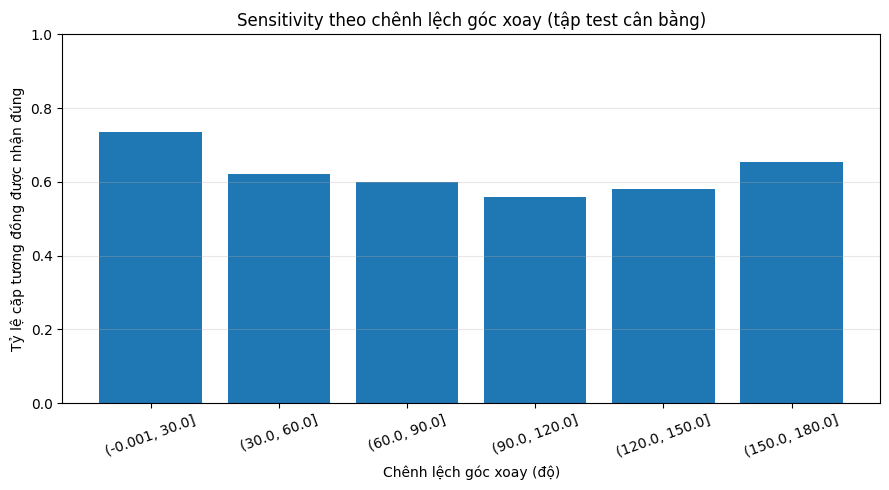

In [28]:
# 6.11. Tỷ lệ nhận đúng cặp tương đồng theo chênh lệch góc (hash chính, ngưỡng từ calibration)
def circular_angle_diff(angle_1, angle_2):
    diff = np.abs(angle_1 - angle_2) % 360
    return np.minimum(diff, 360 - diff)


positive_test = test_pairs_bal[test_pairs_bal["label"] == 1].copy()
positive_test["angle_diff"] = circular_angle_diff(
    positive_test["angle_1"].to_numpy(), positive_test["angle_2"].to_numpy())
positive_test["detected"] = positive_test["hamming_distance"] <= res_gray["threshold"]
positive_test["angle_bin"] = pd.cut(
    positive_test["angle_diff"], bins=[0, 30, 60, 90, 120, 150, 180], include_lowest=True)

angle_summary = (
    positive_test.groupby("angle_bin", observed=True)
    .agg(so_cap=("detected", "size"),
         khoang_cach_TB=("hamming_distance", "mean"),
         ti_le_nhan_dung=("detected", "mean"))
)
print(angle_summary.round(4).to_string())

negative_test = test_pairs_bal[test_pairs_bal["label"] == 0]
print("Specificity trên cặp âm test (tham chiếu):",
      round(float((negative_test["hamming_distance"] > res_gray["threshold"]).mean()), 4))

plt.figure(figsize=(9, 5))
plt.bar(range(len(angle_summary)), angle_summary["ti_le_nhan_dung"].to_numpy())
plt.xticks(range(len(angle_summary)), [str(b) for b in angle_summary.index], rotation=20)
plt.ylim(0, 1)
plt.xlabel("Chênh lệch góc xoay (độ)")
plt.ylabel("Tỷ lệ cặp tương đồng được nhận đúng")
plt.title("Sensitivity theo chênh lệch góc xoay (tập test cân bằng)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#### 6.11.1. Nhận xét kết quả theo chênh lệch góc

| Chênh lệch góc | Số cặp | Hamming distance trung bình | Tỷ lệ nhận đúng |
|---|---:|---:|---:|
| 0–30° | 331 | 37.884,7855 | 0.7341 |
| 30–60° | 348 | 40.945,8563 | 0.6207 |
| 60–90° | 354 | 42.234,4294 | 0.5989 |
| 90–120° | 345 | 42.991,2348 | 0.5594 |
| 120–150° | 337 | 41.942,2226 | 0.5816 |
| 150–180° | 285 | 39.777,7965 | 0.6526 |

Tỷ lệ nhận đúng giảm từ 0.7341 ở bin 0–30° xuống mức thấp nhất 0.5594 ở bin 90–120°, sau đó tăng lên 0.6526 ở bin 150–180°. Vì vậy, kết quả không cho thấy xu hướng giảm đơn điệu theo chênh lệch góc. Hamming distance trung bình cũng đạt cao nhất ở bin 90–120° rồi giảm ở các bin lớn hơn. Specificity tham chiếu trên các cặp âm test là 0.7025.

Các bin có số cặp hữu hạn (285–354); chưa có khoảng tin cậy để đánh giá độ chắc chắn của chênh lệch giữa các bin. Kết quả gợi ý hash nhạy với góc nhìn, nhưng chưa đủ để kết luận một quy luật đơn điệu hoặc bất biến xoay.
